# Averaging — Theorem 6·7과 Table 2

[공통 분석 파이프라인](00_Common_analysis_pipeline.ipynb) · [앞선 SGD 분석](3_2_2_Figure_2_2A_StochasticGradientDescent.ipynb) · [SGD with averaging 원본 코드](../2_Stochastic_BoundedVariance/B_StochasticGradientDescentWithAveraging.py) · [Primal averaging 원본 코드](../2_Stochastic_BoundedVariance/C_StochasticGradientDescentWithPrimalAveraging.py) · [논문](https://proceedings.mlr.press/v99/taylor19a.html)

이 노트북에서는 앞선 SGD의 $d_k$를 포함해 세 방법의 함수값 계수를 $D_k$로 통일해 쓴다. 평균 가중치 $d_k$와 구분하기 위한 표기다.

앞선 SGD 분석에서 얻은 결과를 출발점으로 삼자. Theorem 5에 고정 step-size $\delta_k=1/L$를 적용하면

$$D_N=N,\qquad e_k=\frac{k+2}{2L},\qquad
\sum_{k=0}^{N-1}e_k=\frac{N(N+3)}{4L}.$$

함수값 계수는 $O(N)$으로 증가하지만, 오차 계수의 누적합은 $O(N^2)$으로 증가한다. 따라서 최종 함수값 상한에서 분산에 곱해지는 계수 $(\sum e_k)/D_N$은 $O(N)$으로 커진다. **마지막 반복점 대신 평균점을 사용하면, 함수값 계수의 증가를 유지하면서 오차 계수의 누적합이 커지는 속도를 낮출 수 있을까?**

SGD에서 사용한 매끄러운 볼록함수와 bounded variance 가정, Gram 표현을 통한 LMI/SDP 구성은 그대로 사용한다. 최종 상한에서는 앞서와 마찬가지로 $(\sum e_k)/D_N$이 분산 항의 크기를 결정한다. 이번에 바꾸는 것은 평균점을 만드는 방법과 oracle의 평가점이다. 공통 파이프라인의 다섯 단계를 두 알고리즘에 각각 적용한 뒤, 마지막에는 각 정리의 계수 합을 이용해 Table 2의 수렴률을 비교한다.

| 공통 단계 | A. SGD with averaging에서의 질문 | B. Primal averaging에서의 질문 |
| --- | --- | --- |
| 1단계 · 알고리즘과 가정 | SGD 갱신 뒤에 평균을 계산하면 무엇이 달라지는가? | 평균점을 먼저 정하고 그 점에서 oracle을 평가하면 무엇이 달라지는가? |
| 2단계 · Parameterized potential 설정 | $z_k$의 함수값과 $x_k$의 거리항을 어떻게 함께 담는가? | $y_k$의 함수값과 $x_k$의 거리항을 어떻게 함께 담는가? |
| 3단계 · LMI/SDP로 계수 수치 탐색 | $D_N$을 키운 뒤 오차 계수의 누적합을 얼마나 줄일 수 있는가? | 알고리즘이 정한 $D_k$를 유지하면서 오차 계수의 누적합을 얼마나 줄일 수 있는가? |
| 4단계 · 계수 패턴 관찰과 단순화 | 단순한 potential에서도 $e_k$의 증가를 억제할 수 있는가? | 추가 오차 항 없이 일정한 $e_k$를 얻을 수 있는가? |
| 5단계 · 해석적 potential inequality와 수렴률 | 관찰한 구조를 Theorem 6으로 어떻게 증명하는가? | 관찰한 구조를 Theorem 7로 어떻게 증명하는가? |

## A. SGD with averaging

### 1단계 · 알고리즘과 가정

먼저 SGD 갱신 뒤에 새 반복점을 기존 평균에 반영한다.

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
z_{k+1}^{(i)}=\frac{x_{k+1}^{(i)}+kz_k}{k+1},\qquad
\delta_k=\frac1L.$$

이 과정을 반복하면 $z_N$은 $x_1,\ldots,x_N$의 산술평균이 된다. 일반적인 SGD와 같은 점 $x_k$에서 oracle을 평가하지만, 함수값을 분석할 출력은 $x_N$에서 $z_N$으로 바뀐다.

가정은 앞선 SGD와 같다. $f\in\mathcal F_L$, $f_\star=f(x_\star)$이고, stochastic oracle은

$$\mathbb E_iG(v;i)=\nabla f(v),\qquad
\mathbb E_i\|G(v;i)-\nabla f(v)\|^2\le\sigma^2$$

를 만족한다. 아래 수치 모형은 원본 averaging 코드를 따른다. 수식의 상태 $k$는 코드의 상태 인덱스 `k+1`에 대응하므로, 업데이트 루프 `k=1,...,N`은 수식의 $0\to1,\ldots,N-1\to N$을 나타낸다.

알고리즘과 출력점을 정했으므로, 다음 단계에서는 $z_k$의 함수값과 $x_k$의 거리항을 함께 담을 potential을 선택한다.


In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util

import cvxpy as cp
import matplotlib.pyplot as plt
import mosek
import numpy as np
from IPython.display import Markdown, display

repo_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "2_Stochastic_BoundedVariance/B_StochasticGradientDescentWithAveraging.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Repository root not found.")
license_path = repo_root / "mosek.lic"
if license_path.is_file():
    mosek.Env().putlicensepath(str(license_path))

adapter_path = repo_root / "2_Stochastic_BoundedVariance/saveData.py"
spec = importlib.util.spec_from_file_location("averaging_saveData", adapter_path)
solver_adapter = importlib.util.module_from_spec(spec)
spec.loader.exec_module(solver_adapter)
solve = solver_adapter.solve

### 2단계 · Parameterized potential 설정

1단계에서 정한 출력은 평균점 $z_k$이고, SGD 갱신은 $x_k$에서 이루어진다. 두 상태를 함께 담기 위해 다음 형태의 potential을 사용한다. A에서는 $v_k=z_k$, 뒤의 B에서는 $v_k=y_k$이다.

$$\phi_k^f=a_k\|v_k-x_\star\|^2+b_k\|\nabla f(v_k)\|^2
+2c_k\langle\nabla f(v_k),v_k-x_\star\rangle
+D_k(f(v_k)-f_\star)+a'_k\|x_k-x_\star\|^2.$$

평균점과 최적점 사이의 거리 제곱, gradient norm 제곱, 두 벡터의 내적에 관한 항은 $Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$로 묶는다. 함수값은 평균점에서 평가하고, 별도의 거리항은 SGD 반복점에서 평가한다. 코드의 `d[k+1]`은 함수값 계수 $D_k$, `ap[k+1]`은 거리항 계수 $a'_k$에 대응한다.

중간 계수를 자유롭게 탐색하는 설정과, 단순한 potential로 제한하는 설정을 비교한다. 두 설정의 최종 거리항도 다르므로 경계 조건을 함께 정한다.


| `relax` | 중간 상태 $1\le k<N$ | 초기 상태 | 최종 상태 |
| --- | --- | --- | --- |
| 0 | $Q_k,D_k,a'_k$를 자유롭게 탐색 | $Q_0=0,D_0=0,a'_0=L/2$ | $Q_N=0,D_N=\tau,a'_N=0$ |
| 1 | $Q_k=0,a'_k=L/2$로 고정하고 $D_k$를 탐색 | 동일 | $Q_N=0,D_N=\tau,a'_N=L/2$ |


초기 potential은 $\phi_0^f=(L/2)\|x_0-x_\star\|^2$이다. 각 단계에서

$$\mathbb E_i\phi_{k+1}^f\le\phi_k^f+e_k\sigma^2$$

를 만족하는 계수를 찾으면, 전체 기대값을 취해 합할 때 중간 potential이 소거된다. 최종 potential의 비음수 거리항을 버리고 $D_N>0$으로 나누면

$$\mathbb E[f(z_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2D_N}
+\frac{\sum_{k=0}^{N-1}e_k}{D_N}\sigma^2$$

를 얻는다. 이 상한을 바탕으로 다음 단계의 목적함수를 정한다. 먼저 $D_N$을 크게 만들고, 그 수준을 유지하면서 $\sum e_k$를 줄인다. 수치 결과를 비교할 때도 최종 상한에 들어가는 비율 $(\sum e_k)/D_N$을 함께 비교한다.

아래 실험의 기본 설정은

$$L=1,\qquad \mu=0,\qquad n=2,\qquad N=100$$

이다. Potential과 경계 조건을 정했으므로, 이제 한 단계에서의 potential 변화에 대한 부등식을 Gram 표현으로 옮겨 LMI/SDP를 구성한다.


In [2]:
L = 1.0
m = 0.0
n = 2
N_FIGURE = 100
solver = "MOSEK"
tolerance = 1e-8
tol_reopt = 1e-5
verbose = False

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 11,
})

### 3단계 · LMI/SDP로 계수 수치 탐색

2단계에서 선택한 potential과 경계 조건을 SDP의 변수와 제약으로 옮긴다. 앞선 SGD와 마찬가지로 현재·다음 potential의 차이를 Gram 행렬과 함수값에 대한 선형식으로 쓰고, interpolation 부등식과 분산 조건의 비음수 가중합을 더한다.

이번에 달라진 부분은 평균점 $z_k$와 oracle 결과마다 달라지는 다음 평균점 $z_{k+1}^{(i)}$가 필요하다는 점이다. 이 점들을 Gram 표현에 포함하면, 나머지 LMI는 앞선 SGD와 같은 방식으로 구성할 수 있다.

#### 한 단계의 Gram 표현

위치와 함수값의 기준을 옮겨 $x_\star=0$, $f_\star=0$으로 둔다. 또한 미분 가능한 볼록함수의 최적성 조건에 따라 $\nabla f(x_\star)=0$이다. 한 단계에서 필요한 실제 벡터들을

$$P=[\,x_k\quad z_k\quad\nabla f(z_k)\quad s_1\ \cdots\ s_n
\quad h_1\ \cdots\ h_n\,],\qquad
s_i=G(x_k;i),\quad h_i=\nabla f(z_{k+1}^{(i)})$$

로 모으고, $G=P^\top P$를 Gram 행렬로 정의한다. 아래 코드는 $P$의 열을 고르는 계수벡터를 만든다. $n=2$이면 $P$에는 일곱 개의 열이 있으므로 $G$는 $7\times7$ 행렬이다.


In [3]:
N = N_FIGURE
alpha = 0
delta = lambda k: 1 / L / (k + 1)**alpha
dimG = 3 + 2 * n
dimF = n + 2
nbPts = 3 + n

xk = np.zeros(dimG)
xk[0] = 1
zk = np.zeros(dimG)
zk[1] = 1
xs = np.zeros(dimG)
gzk = np.zeros(dimG)
gzk[2] = 1
Gxk = np.zeros((n, dimG))
Gxk[:, 3:n + 3] = np.eye(n)
gxk = np.sum(Gxk, axis=0) / n
gzk1 = np.zeros((n, dimG))
gzk1[:, 3 + n:3 + 2 * n] = np.eye(n)
gxs = np.zeros(dimG)


함수값도 한 벡터로 모은다. 앞에서 $f_\star=0$으로 두었으므로

$$\mathbf F=(f(z_k),f(x_k),f(z_{k+1}^{(1)}),\ldots,
f(z_{k+1}^{(n)}))^\top$$

로 쓸 수 있다. 다음 반복점과 평균점은 $P$에 새 열을 추가하지 않고, 알고리즘의 갱신식으로 표현한다.

$$\mathbf x_{k+1}^{(i)}=\mathbf x_k-\delta_k\mathbf s_i,\qquad
\mathbf z_{k+1}^{(i)}
=\frac{\mathbf x_{k+1}^{(i)}+k\mathbf z_k}{k+1}.$$

여기서 굵은 기호는 실제 벡터를 $P$의 열들의 선형결합으로 나타내는 계수벡터다. 예를 들어 $P\mathbf s_i=G(x_k;i)$이고, $P\mathbf z_{k+1}^{(i)}=z_{k+1}^{(i)}$이다. 아래 코드의 평균 갱신식은 업데이트에 1부터 번호를 매기므로 분모가 `k`로 나타난다.


In [4]:
fzk = np.zeros(dimF)
fzk[0] = 1
fxk = np.zeros(dimF)
fxk[1] = 1
fzk1 = np.zeros((n, dimF))
fzk1[:, 2:n + 2] = np.eye(n)
fxs = np.zeros(dimF)

xk1 = lambda k: np.ones((n, 1)) * xk - delta(k) * Gxk
zk1 = lambda k: xk1(k) / k + (k - 1) / k * zk
statesKG = np.column_stack((zk - xs, gzk))
statesKF = fzk


#### Interpolation 부등식과 분산 조건을 Gram 행렬로 표현하기

각 점의 위치, gradient, 함수값을 $x_i,g_i,f_i$라고 쓰면, 매끄러운 볼록함수의 interpolation 부등식은

$$\mathcal I_{i,j}=f_i-f_j-\langle g_j,x_i-x_j\rangle
-\frac1{2L}\|g_i-g_j\|^2\ge0$$

이다. $P\mathbf x_i=x_i$, $P\mathbf g_i=g_i$인 **열벡터**를 모아
$T_{i,j}=[\,\mathbf x_i\ \mathbf x_j\ \mathbf g_i\ \mathbf g_j\,]$로 정의하면

$$\mathcal I_{i,j}
=\mathbf F^\top(\mathbf f_i-\mathbf f_j)
+\langle G,T_{i,j}MT_{i,j}^\top\rangle,\qquad G=P^\top P$$

로 쓸 수 있다. $\mathbf f_i$는 $\mathbf F$에서 $f_i$를 고르는 계수벡터이며, 행렬 내적은 $\langle G,A\rangle=\operatorname{Tr}(G^\top A)$이다. 코드의 `TT = np.vstack(...)`는 $T_{i,j}^\top$에 해당하므로, `TT.T @ M @ TT`가 위 이차항의 계수행렬이다.

분산 조건도 같은 Gram 행렬로 표현한다. Oracle 계수벡터의 평균을 $\overline{\mathbf s}=n^{-1}\sum_i\mathbf s_i$라고 하면

$$A_{\rm var}
=\frac1n\sum_i(\mathbf s_i-\overline{\mathbf s})
(\mathbf s_i-\overline{\mathbf s})^\top,\qquad
\langle G,A_{\rm var}\rangle\le\sigma^2.$$

Unbiasedness에 의해 $P\overline{\mathbf s}=\nabla f(x_k)$이므로, 이 식은 원래의 bounded variance 조건과 같다.


In [5]:
M = np.array([
    [-L * m, L * m, m, -L],
    [L * m, -L * m, -m, L],
    [m, -m, -1, 1],
    [-L, L, 1, -1],
]) / (2 * (L - m))
Avar = np.zeros((dimG, dimG))
for i in range(1, n + 1):
    Avar = Avar + np.outer(Gxk[i - 1] - gxk, Gxk[i - 1] - gxk) / n


#### Potential 계수와 경계 조건을 코드로 정의하기

이제 2단계에서 선택한 potential의 계수와 경계 조건을 코드로 정의한다. A에서는 $v_k=z_k$이므로

$$\phi_k^f=
\begin{pmatrix}z_k-x_\star\\\nabla f(z_k)\end{pmatrix}^{\!\top}
(Q_k\otimes I)
\begin{pmatrix}z_k-x_\star\\\nabla f(z_k)\end{pmatrix}
+D_k(f(z_k)-f_\star)+a'_k\|x_k-x_\star\|^2,\qquad
Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$$

이다. 아래 코드에서는 두 설정의 중간 단계 계수를 변수로 선언하고, 초기·최종 경계값을 지정한다. 계수를 자유롭게 탐색하는 설정에서는 $Q_k,D_k,a'_k$를 탐색하고, 단순한 potential로 제한한 설정에서는 $Q_k=0,a'_k=L/2$로 둔 채 $D_k$를 탐색한다. 최종 거리항은 각각 $a'_N=0$과 $a'_N=L/2$이다.

중간 단계의 $Q_k$에는 별도의 PSD 제약을 부과하지 않는다. $Q_k$는 potential의 계수행렬이며, 실제 벡터의 내적을 모은 Gram 행렬 $G\succeq0$과는 역할이 다르다. 코드의 `d`에는 함수값 계수 $D_k$가 저장된다.


In [6]:
averaging_models = {}
for relax in (0, 1):
    tau = cp.Variable(name="tau")
    Q = {1: np.zeros((2, 2)), N + 1: np.zeros((2, 2))}
    d = {1: 0, N + 1: tau}
    ap = {1: L / 2, N + 1: 0 if relax == 0 else L / 2}
    lam, e = {}, {}
    for k in range(1, N + 1):
        if k < N:
            d[k + 1] = cp.Variable(name=f"d_{k + 1}")
            ap[k + 1] = cp.Variable(name=f"ap_{k + 1}") if relax == 0 else L / 2
            Q[k + 1] = (cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
                      if relax == 0 else np.zeros((2, 2)))
        lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")
        e[k] = cp.Variable(name=f"e_{k}")
    averaging_models[relax] = {
        "tau": tau, "Q": Q, "d": d, "ap": ap, "lam": lam, "e": e,
        "cons_SDP": {}, "cons_LIN": {}, "cons": [tau >= 0],
    }


#### 한 단계 potential 차이의 행렬을 만들기

평균점의 위치와 gradient를 고르는 행렬은
$E_k=[\mathbf z_k-\mathbf x_\star\quad\mathbf g_{z_k}]$이다. 이를 사용하면 현재 potential의 이차항에 대응하는 계수행렬과, 다음 potential의 이차항을 oracle 결과에 대해 평균한 계수행렬은 각각

$$V_k=E_kQ_kE_k^\top+a'_k\mathbf x_k\mathbf x_k^\top,$$
$$\overline V_{k+1}
=\frac1n\sum_i\left[
E_{k+1}^{(i)}Q_{k+1}(E_{k+1}^{(i)})^\top
+a'_{k+1}\mathbf x_{k+1}^{(i)}
(\mathbf x_{k+1}^{(i)})^\top\right]$$

이다. 아래에서는 먼저 $\overline V_{k+1}-V_k-e_kA_{\rm var}$를 만들고, 함수값 계수의 차이도 별도로 계산한다. 다음 셀에서 interpolation 부등식의 가중합을 더하면 한 단계 부등식을 보장하는 SDP 제약을 얻는다.


In [7]:
for relax, model in averaging_models.items():
    Q, d, ap, e = (model[key] for key in ("Q", "d", "ap", "e"))
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        XK1, ZK1 = xk1(k), zk1(k)
        cons_SDP[k] = -statesKG @ Q[k] @ statesKG.T
        cons_SDP[k] = cons_SDP[k] - ap[k] * np.outer(xk - xs, xk - xs) - e[k] * Avar
        cons_LIN[k] = -d[k] * statesKF
        for i in range(1, n + 1):
            statesK1G = np.column_stack((ZK1[i - 1] - xs, gzk1[i - 1]))
            statesK1F = fzk1[i - 1]
            cons_SDP[k] = cons_SDP[k] + statesK1G @ Q[k + 1] @ statesK1G.T / n
            cons_SDP[k] = cons_SDP[k] + ap[k + 1] * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs) / n
            cons_LIN[k] = cons_LIN[k] + statesK1F * d[k + 1] / n


Interpolation에 사용할 점은
$\{\star,x_k,z_k,z_{k+1}^{(1)},\ldots,z_{k+1}^{(n)}\}$이다.
서로 다른 두 점의 각 순서쌍에 비음수 multiplier $\lambda_{i,j}$를 붙인다.

$$R_k=\overline V_{k+1}-V_k-e_kA_{\rm var}
+\sum_{i\ne j}\lambda_{i,j}T_{i,j}MT_{i,j}^\top\preceq0,$$
$$D_{k+1}\overline{\mathbf f}_{k+1}-D_k\mathbf f_k
+\sum_{i\ne j}\lambda_{i,j}(\mathbf f_i-\mathbf f_j)=0,
\qquad \lambda_{i,j}\ge0,\quad e_k\ge0.$$

여기서 $\mathbf f_k=\mathbf f_{z_k}$이고,
$\overline{\mathbf f}_{k+1}=n^{-1}\sum_i\mathbf f_{z_{k+1}^{(i)}}$이다.
두 번째 식으로 함수값 계수를 소거하고, 첫 번째 LMI로 남은 이차항이 0 이하임을 보장한다. 두 potential 설정 모두 같은 $7\times7$ LMI를 사용한다.


In [8]:
for relax, model in averaging_models.items():
    lam, e = model["lam"], model["e"]
    cons_SDP, cons_LIN, cons = (model[key] for key in ("cons_SDP", "cons_LIN", "cons"))
    for k in range(1, N + 1):
        ZK1 = zk1(k)
        X = {1: xs, 2: xk, 3: zk}
        G = {1: gxs, 2: gxk, 3: gzk}
        F = {1: fxs, 2: fxk, 3: fzk}
        for i in range(1, n + 1):
            X[3 + i], G[3 + i], F[3 + i] = ZK1[i - 1], gzk1[i - 1], fzk1[i - 1]
        for i in range(1, nbPts + 1):
            for j in range(1, nbPts + 1):
                if j != i:
                    TT = np.vstack((X[i], X[j], G[i], G[j]))
                    cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                    cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (F[i] - F[j])
        cons = cons + [cons_SDP[k] << 0, cons_LIN[k] == 0, lam[k] >= 0, e[k] >= 0]
    model["cons"] = cons


#### 함수값 계수를 키운 뒤 오차 계수의 누적합을 줄이기

먼저 위 제약 아래에서 최종 함수값 계수 $\tau=D_N$을 최대화한다. 그다음 이 값을 거의 유지하면서 오차 계수의 누적합을 최소화한다.

$$\tau^\star=\max\{\tau:\text{위 제약}\},\qquad
\min\left\{\sum_{k=0}^{N-1}e_k:
\text{위 제약},\ \tau\ge\tau^\star-10^{-5}\right\}.$$

첫 번째 목적함수는 $D_N$을 크게 만드는 데 집중한다. 첫 번째 최적화에서는 $\sum e_k$를 직접 줄이지 않으므로, 두 번째 최적화에서 분산 항의 크기를 조절한다. 아래 코드는 첫 번째 최적화를 실행하고, 얻은 $D_N$과 오차 계수의 누적합을 저장한다.


In [9]:
for relax, model in averaging_models.items():
    tau, e, cons = model["tau"], model["e"], model["cons"]
    accumulated_ek = 0
    for k in range(1, N + 1):
        accumulated_ek = accumulated_ek + e[k]
    obj = -tau
    solver_opt = {
        "solver": solver, "verbose": bool(verbose),
        "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance},
    }
    started = perf_counter()
    solverDetails = cp.Problem(cp.Minimize(obj), cons)
    solve(solverDetails, **solver_opt)
    model["stage1"] = {
        "d_N": -float(obj.value), "sum_e": float(accumulated_ek.value),
        "status": solverDetails.status,
    }
    model["accumulated_ek"] = accumulated_ek
    model["seconds_stage1"] = perf_counter() - started


이제 첫 번째 최적화에서 얻은 $D_N$의 하한을 제약에 추가하고 $\sum e_k$를 최소화한다. 재최적화에서는 원본 코드와 동일하게 solver의 기본 설정을 사용한다. 두 최적화의 결과는 다음 표에서 함께 비교한다.


In [10]:
for relax, model in averaging_models.items():
    tau, cons = model["tau"], model["cons"]
    cons = cons + [tau >= model["stage1"]["d_N"] - tol_reopt]
    solver_opt = {"solver": solver, "verbose": bool(verbose)}
    started = perf_counter()
    solverDetails = cp.Problem(cp.Minimize(model["accumulated_ek"]), cons)
    solve(solverDetails, **solver_opt)
    model["cons"] = cons
    model["problem"] = solverDetails
    model["seconds"] = model["seconds_stage1"] + perf_counter() - started


#### 두 차례 최적화가 상한을 어떻게 바꾸었는가?

$Q_k$에서 $a_k,b_k,c_k$를 추출하고, 단계별 $e_k$로부터 누적합 $\sum_{t=0}^{k-1}e_t$를 계산한다. 각 최적화에서 얻은 $D_N$, 오차 계수의 누적합, 그리고 함수값 상한에 들어가는 비율 $(\sum e_k)/D_N$을 함께 비교한다.


In [11]:
averaging_results = {}
for relax, model in averaging_models.items():
    Q, d, ap, e, lam = (model[key] for key in ("Q", "d", "ap", "e", "lam"))
    qvalues = np.stack([np.asarray(Q[k].value if isinstance(Q[k], cp.Expression)
                                  else Q[k]) for k in range(1, N + 2)])
    dvalues = np.array([float(d[k].value if isinstance(d[k], cp.Expression)
                             else d[k]) for k in range(1, N + 2)])
    apvalues = np.array([float(ap[k].value if isinstance(ap[k], cp.Expression)
                              else ap[k]) for k in range(1, N + 2)])
    evalues = np.array([float(e[k].value) for k in range(1, N + 1)])
    averaging_results[relax] = {
        "a": qvalues[:, 0, 0], "b": qvalues[:, 1, 1], "c": qvalues[:, 0, 1],
        "d": dvalues, "ap": apvalues, "e": evalues,
        "ec": np.r_[0., np.cumsum(evalues)],
        "multipliers": np.stack([lam[k].value for k in range(1, N + 1)]),
        "d_N": float(dvalues[-1]), "sum_e": float(evalues.sum()),
        "stage1": model["stage1"], "status": model["problem"].status,
        "N": N, "L": L, "n": n, "relax": relax, "seconds": model["seconds"],
    }


In [12]:
for relax, model in averaging_models.items():
    result = averaging_results[relax]
    matrices = np.stack([model["cons_SDP"][k].value for k in range(1, N + 1)])
    equalities = np.stack([model["cons_LIN"][k].value for k in range(1, N + 1)])
    result["residuals"] = {
        "R": matrices, "equality": equalities,
        "lmi_violation": max(0., float(np.linalg.eigvalsh(matrices).max())),
        "equality_violation": float(np.abs(equalities).max()),
        "multiplier_violation": max(0., float(-result["multipliers"].min())),
        "variance_multiplier_violation": max(0., float(-result["e"].min())),
    }
headers = ["설정", "최적화 단계", r"$D_N$", r"$\sum_{k=0}^{N-1}e_k$",
           r"$(\sum e_k)/D_N$"]
rows = []
for relax, result in averaging_results.items():
    for stage, d_final, error_sum in (
        ("1: 함수값 계수 최대화", result["stage1"]["d_N"], result["stage1"]["sum_e"]),
        ("2: 누적 오차 최소화", result["d_N"], result["sum_e"]),
    ):
        rows.append((str(relax), stage, f"{d_final:.8f}", f"{error_sum:.6f}",
                     f"{error_sum / d_final:.6f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))
for relax, result in averaging_results.items():
    if result["status"] not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"averaging relax={relax}: {result['status']}")
    print(f"relax={relax}: {result['status']}")


| 설정 | 최적화 단계 | $D_N$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/D_N$ |
| --- | --- | --- | --- | --- |
| 0 | 1: 함수값 계수 최대화 | 102.00000086 | 5216.906032 | 51.146137 |
| 0 | 2: 누적 오차 최소화 | 101.99990306 | 48.634944 | 0.476814 |
| 1 | 1: 함수값 계수 최대화 | 100.11848875 | 28319.771650 | 282.862556 |
| 1 | 2: 누적 오차 최소화 | 100.11846808 | 52.604190 | 0.525419 |

relax=0: optimal
relax=1: optimal


`relax=1`에서 오차 계수의 누적합은 첫 번째 최적화의 약 $28319.77$에서 두 번째 최적화의 약 $52.60$으로 줄었다. 두 번째 최적화는 첫 번째 최적화에서 찾은 $D_N$을 거의 유지하면서 $\sum e_k$와 최종 상한의 분산 계수를 크게 낮춘다. 이 실험은 함수값 계수를 먼저 최대화하고, 그 수준을 유지하는 해 가운데 오차 계수의 누적합이 작은 해를 찾도록 두 목적함수로 차례로 최적화했다.

모형에 넣은 재최적화 제약은 $\tau\ge\tau^\star-10^{-5}$이다. 정확히 이 제약을 만족하는 해라면 $D_N$의 감소량은 $10^{-5}$ 이하여야 한다. 저장된 수치해에서 이 차이가 조금 더 큰 것은 solver의 수치 허용오차가 포함된 결과다.

이제 최종 수치만이 아니라, 그 결과를 만든 계수 수열을 살펴본다. 자유롭게 탐색한 설정과 $Q_k=0$, $a'_k=L/2$로 제한한 설정을 비교하면, 단순한 potential로도 어떤 계수 구조를 유지할 수 있는지 볼 수 있다.


### 4단계 · 계수 패턴 관찰과 단순화

3단계에서는 두 차례 최적화로 $D_N$과 오차 계수의 누적합을 구하고, 오차 계수의 누적합을 함수값 계수로 나눈 비율도 비교했다. 이제 계수 수열의 변화를 살펴보며, 반복 횟수에 관계없이 부등식이 성립함을 증명할 수 있는 단순한 형태를 찾는다.

#### 거리항·함수값·오차 계수의 변화를 함께 보기

아래 네 패널은 $a'_k$, $D_k$, $e_k$, $\sum_{t<k}e_t$를 보여 준다. 두 설정은 최종 거리항 $a'_N$도 다르므로, 각 곡선을 비교할 때 이 경계 조건의 차이도 함께 고려해야 한다. 특히 끝부분의 거리항과 오차 계수가 함께 어떻게 바뀌는지 살펴보자.


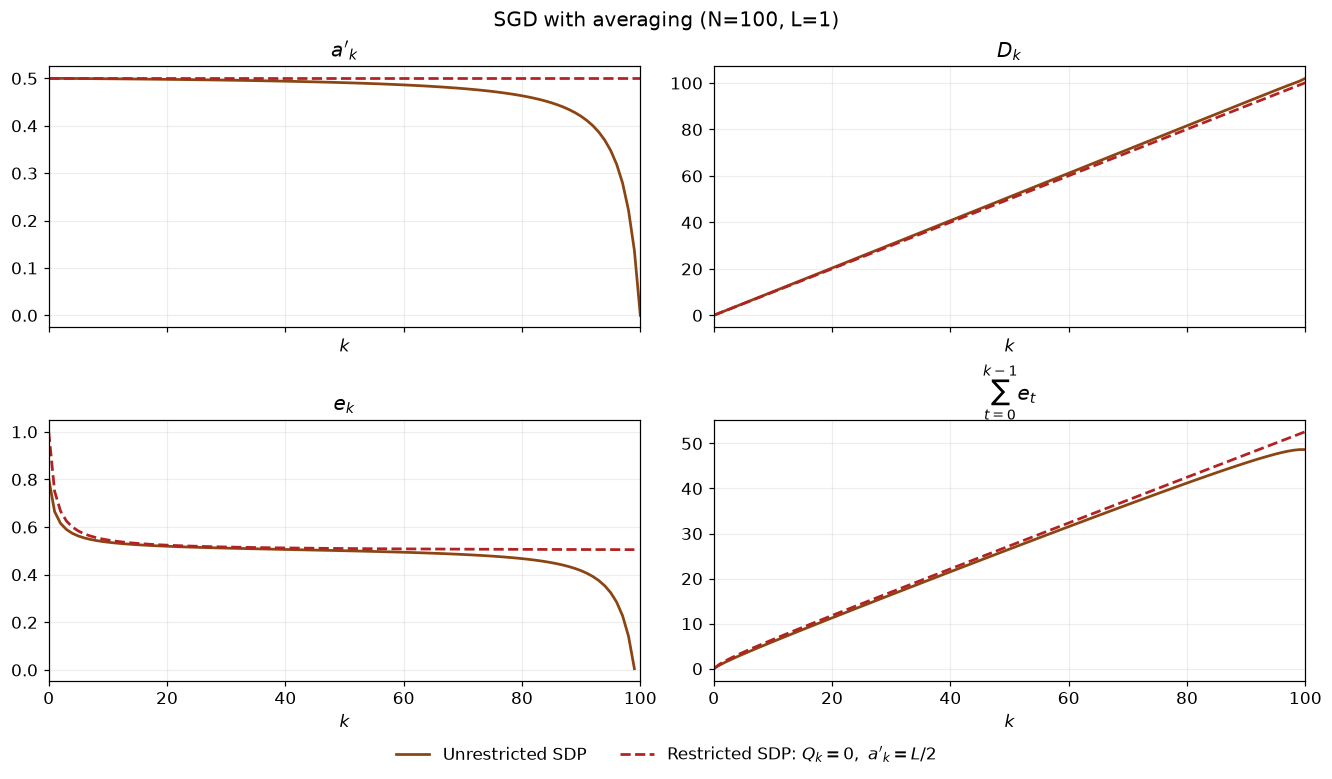

In [13]:
styles_avg = {0: ("Unrestricted SDP", "saddlebrown", "-"),
              1: (r"Restricted SDP: $Q_k=0,\ a'_k=L/2$", "firebrick", "--")}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("ap", "d", "e", "ec"), axes.flat,
                           (r"$a'_k$", r"$D_k$", r"$e_k$", r"$\sum_{t=0}^{k-1}e_t$")):
    for relax, result in averaging_results.items():
        label, color, linestyle = styles_avg[relax]
        ax.plot(np.arange(len(result[key])), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$",
           xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"SGD with averaging (N={N_FIGURE}, L={L:g})")
plt.show()


평균점에 관한 이차항도 따로 살펴본다. $Q_k$의 성분 $a_k,b_k,c_k$는 각각 $z_k$와 최적점 사이의 거리 제곱, gradient norm 제곱, 두 벡터의 내적에 대응한다. 다음 그림은 이 세 계수와 SGD 반복점의 거리항 계수 $a'_k$를 함께 보여 준다.


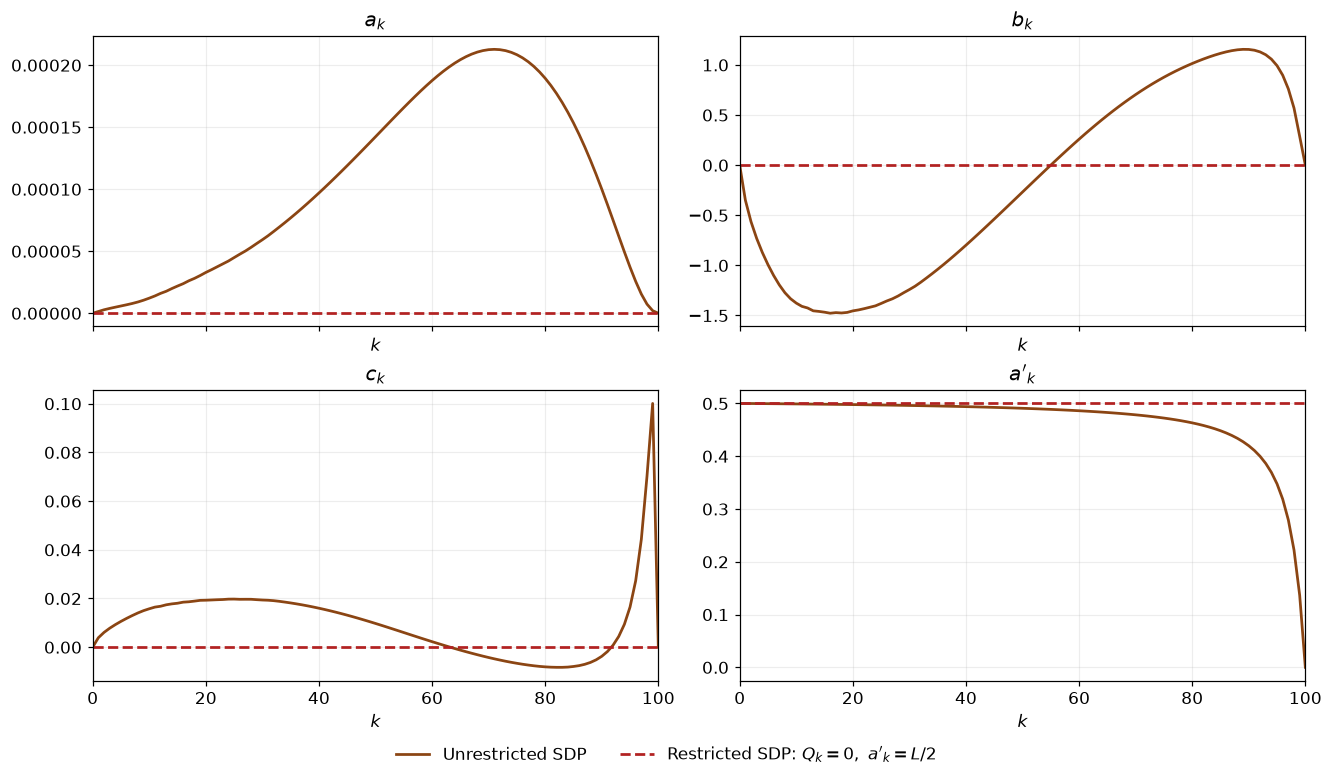

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("a", "b", "c", "ap"), axes.flat,
                           (r"$a_k$", r"$b_k$", r"$c_k$", r"$a'_k$")):
    for relax, result in averaging_results.items():
        label, color, linestyle = styles_avg[relax]
        ax.plot(np.arange(N_FIGURE + 1), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$", xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()


### 5단계 · 해석적 potential inequality와 수렴률

4단계에서 살펴본 제한 potential은 $Q_k=0$, $a'_k=L/2$라는 단순한 구조를 사용한다. 이제 이 구조를 유지하면서 $D_k$와 $e_k$를 명시적으로 선택하고, 한 단계 potential inequality를 증명한다. 수치 수열과의 비교로 계수의 형태를 살펴보고, 이 계수가 모든 단계에서 부등식을 만족한다는 사실은 이어지는 interpolation 가중합으로 증명한다.

#### Theorem 6 — 모든 단계에 사용할 명시적 계수

한 단계에서 평균 가중치를 $d_k\ge0$로 두면 알고리즘은

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
z_{k+1}^{(i)}
=\frac{x_{k+1}^{(i)}+d_kz_k}{d_k+1}$$

이다. 여기서 $d_k$는 평균을 만드는 가중치이며, potential의 함수값 계수는 현재 단계에서 $L\delta_kd_k$, 다음 단계에서 $L\delta_k(d_k+1)$이다. Theorem 6은

$$\begin{aligned}
&L\delta_k(d_k+1)\mathbb E_i[f(z_{k+1}^{(i)})-f_\star]
+\frac L2\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2\\
&\qquad\le L\delta_kd_k(f(z_k)-f_\star)
+\frac L2\|x_k-x_\star\|^2+e_k\sigma^2
\end{aligned}$$

를 다음 계수와 step-size 범위에서 보장한다.

$$e_k=\frac{L\delta_k^2}{2}
\left(1+\frac{L\delta_k}{d_k+1}\right),\qquad
0\le\delta_k\le\frac{1+\sqrt5}{2L}.$$

현재 실험처럼 $\delta_k=1/L$, $d_k=k$로 선택하면 각 단계의 함수값 계수가 이어지고,

$$D_k=k,\qquad a'_k=L/2,\qquad Q_k=0,\qquad
e_k=\frac1{2L}\left(1+\frac1{k+1}\right)$$

를 얻는다. 아래에서는 이 명시적 수열을 만들어 수치해와 비교한다.


In [15]:
k = np.arange(N_FIGURE + 1)
transitions = np.arange(N_FIGURE)
analytical_avg = {
    "a": np.zeros(N_FIGURE + 1), "b": np.zeros(N_FIGURE + 1),
    "c": np.zeros(N_FIGURE + 1), "ap": np.full(N_FIGURE + 1, L / 2),
    "d": k.astype(float), "e": (1 + 1 / (transitions + 1)) / (2 * L),
}
analytical_avg["ec"] = np.r_[0., np.cumsum(analytical_avg["e"])]


수치해에서는 단순한 potential에서도 함수값 계수가 비슷하게 증가하는 모습을 볼 수 있었다. 이제 최종 거리항을 유지하는 `relax=1`의 수치해와 Theorem 6의 명시적 수열을 비교한다. 두 수열은 $Q_0,Q_N,a'_0,a'_N$의 경계 조건 형태가 같지만, 최적화로 정한 $D_N$의 값까지 같다고 가정하지는 않는다.


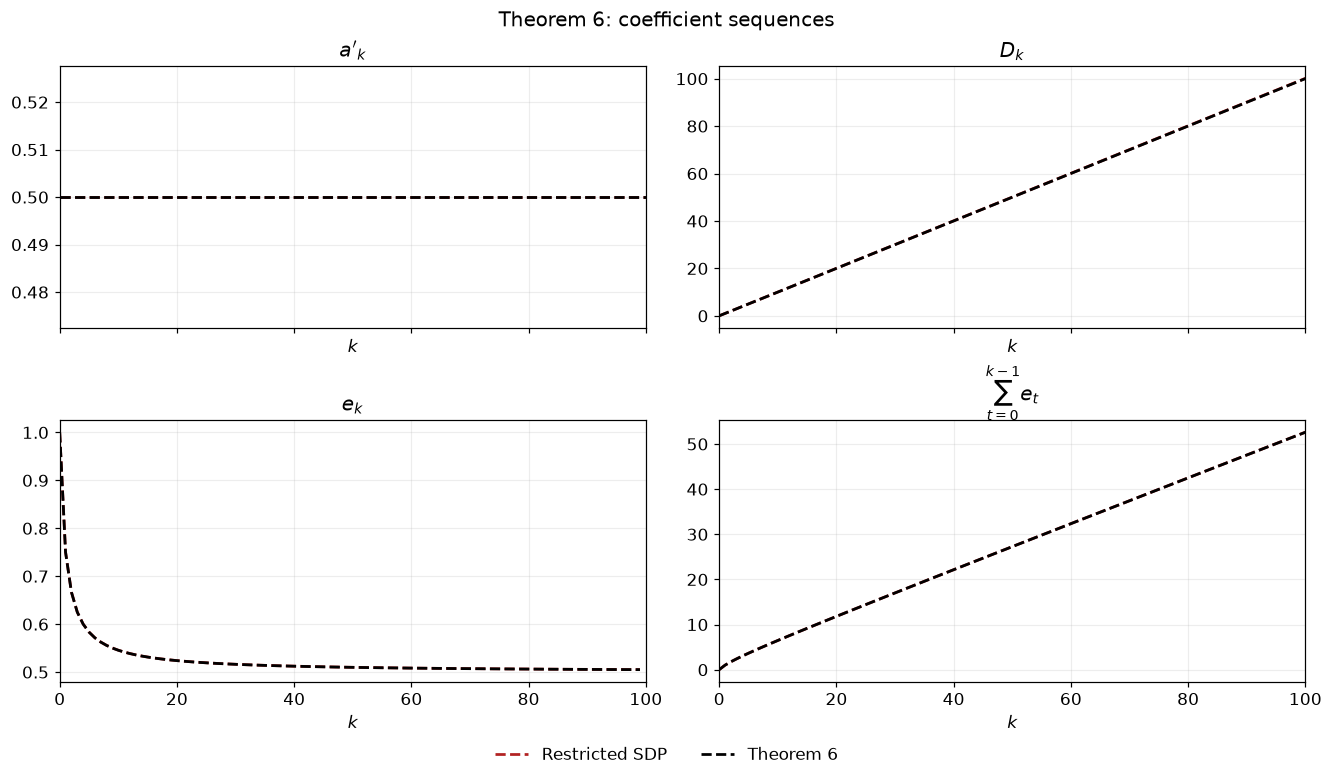

In [16]:
curves_avg = [(averaging_results[1], "Restricted SDP", "firebrick", "--"),
              (analytical_avg, "Theorem 6", "black", "--")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("ap", "d", "e", "ec"), axes.flat,
                           (r"$a'_k$", r"$D_k$", r"$e_k$", r"$\sum_{t=0}^{k-1}e_t$")):
    for result, label, color, linestyle in curves_avg:
        ax.plot(np.arange(len(result[key])), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$",
           xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Theorem 6: coefficient sequences")
plt.show()


In [17]:
headers = ["계수 수열", r"$D_N$", r"$\sum_{k=0}^{N-1}e_k$", r"$(\sum e_k)/D_N$"]
rows = []
for label, result in (("relax=1 수치해", averaging_results[1]),
                      ("Theorem 6", analytical_avg)):
    d_final = result["d"][-1]
    error_sum = result["ec"][-1]
    rows.append((label, f"{d_final:.8f}", f"{error_sum:.8f}",
                 f"{error_sum / d_final:.8f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))


| 계수 수열 | $D_N$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/D_N$ |
| --- | --- | --- | --- |
| relax=1 수치해 | 100.11846808 | 52.60419013 | 0.52541945 |
| Theorem 6 | 100.00000000 | 52.59368876 | 0.52593689 |

그림의 두 곡선은 가깝지만 동일하지 않다. 수치해는 $D_N\approx100.118468$, $\sum e_k\approx52.604190$이고, 정리의 수열은 $D_N=100$, $\sum e_k\approx52.593689$이다. 오차 계수의 누적합만 보면 정리의 수열이 작지만, $D_N$으로 나눈 분산 계수는 수치해가 조금 작다. 상한의 분모도 함께 달라졌기 때문이다.

Theorem 6은 모든 단계에서 부등식을 만족하는 명시적 수열을 제공한다. 이 수열이 SDP로 구한 수치해와 항마다 일치할 필요는 없다. 다음 증명에서는 함수값 계수와 오차 계수의 이러한 형태가 interpolation 부등식의 가중합에서 어떻게 나오는지 살펴본다.


#### Appendix E.2 — 함수값 항을 소거하고 평균 갱신식을 사용하기

한 단계의 평균 가중치를 $d_k\ge0$로 두고, $\mathbb E_i$는 현재 상태를 고정한 조건부 기대값을 뜻한다. Theorem 6의 현재·다음 함수값 계수는 각각 $L\delta_kd_k$, $L\delta_k(d_k+1)$이다. 먼저 **각각 0 이하인 항**들을 다음과 같이 합한다.

$$\begin{aligned}
0\ge{}&
-L\delta_k\mathcal I_{\star,x_k}
-L\delta_k\mathbb E_i\mathcal I_{x_k,z_{k+1}^{(i)}}\\
&-L\delta_kd_k\mathbb E_i\mathcal I_{z_k,z_{k+1}^{(i)}}
+e_k\left(
\mathbb E_i\|G(x_k;i)-\nabla f(x_k)\|^2-\sigma^2
\right).
\end{aligned}$$

함수값 항만 모으면

$$\begin{aligned}
&L\delta_k(f(x_k)-f_\star)
+L\delta_k\mathbb E_i[f(z_{k+1}^{(i)})-f(x_k)]\\
&\qquad+L\delta_kd_k\mathbb E_i[f(z_{k+1}^{(i)})-f(z_k)]\\
&=L\delta_k(d_k+1)\mathbb E_i[f(z_{k+1}^{(i)})-f_\star]
-L\delta_kd_k(f(z_k)-f_\star).
\end{aligned}$$

중간 함수값 $f(x_k)$가 소거되어, 원하는 potential 차이의 함수값 부분이 남는다. 다음으로 두 번째와 세 번째 interpolation의 내적항을 묶는다. 평균 갱신식과 SGD 갱신식에 의해

$$x_k+d_kz_k-(d_k+1)z_{k+1}^{(i)}
=x_k-x_{k+1}^{(i)}=\delta_kG(x_k;i)$$

이므로

$$\begin{aligned}
&L\delta_k\mathbb E_i
\langle\nabla f(z_{k+1}^{(i)}),x_k-z_{k+1}^{(i)}\rangle\\
&\quad+L\delta_kd_k\mathbb E_i
\langle\nabla f(z_{k+1}^{(i)}),z_k-z_{k+1}^{(i)}\rangle\\
&=L\delta_k^2\mathbb E_i
\langle\nabla f(z_{k+1}^{(i)}),G(x_k;i)\rangle.
\end{aligned}$$

첫 번째 interpolation의 내적항은 SGD 반복점의 거리항과 연결된다. Unbiasedness를 사용하면

$$\begin{aligned}
&\frac L2\left(
\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2-\|x_k-x_\star\|^2
\right)\\
&=-L\delta_k\langle\nabla f(x_k),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(x_k;i)\|^2.
\end{aligned}$$

따라서 처음의 가중합은 $0\ge\Delta\phi_k-e_k\sigma^2+\mathcal R_{6,k}$로 쓸 수 있다. 여기서 $\Delta\phi_k$는 Theorem 6의 다음 단계 함수값·거리항에서 현재 단계 함수값·거리항을 뺀 차이다. 아직 완전제곱으로 정리하지 않은 나머지 이차항은

$$\begin{aligned}
\mathcal R_{6,k}={}&
\frac{\delta_k}{2}\|\nabla f(x_k)\|^2
+\frac{\delta_k}{2}\mathbb E_i
\|\nabla f(x_k)-\nabla f(z_{k+1}^{(i)})\|^2\\
&+\frac{d_k\delta_k}{2}\mathbb E_i
\|\nabla f(z_k)-\nabla f(z_{k+1}^{(i)})\|^2\\
&+L\delta_k^2\mathbb E_i
\langle\nabla f(z_{k+1}^{(i)}),G(x_k;i)\rangle\\
&+\left(e_k-\frac{L\delta_k^2}{2}\right)
\mathbb E_i\|G(x_k;i)\|^2
-e_k\|\nabla f(x_k)\|^2
\end{aligned}$$

이다. 마지막 줄에서는 unbiasedness로부터 얻는
$\mathbb E_i\|G(x_k;i)-\nabla f(x_k)\|^2
=\mathbb E_i\|G(x_k;i)\|^2-\|\nabla f(x_k)\|^2$를 사용했다.


#### Appendix E.2 — 오차 계수를 선택하고 완전제곱으로 정리하기

이제 $\mathcal R_{6,k}\ge0$임을 보이면 된다. 먼저 $\nabla f(z_{k+1}^{(i)})$를 포함하는 항을 모아 완전제곱식으로 정리한다.

$$\begin{aligned}
&\frac{(d_k+1)\delta_k}{2}\mathbb E_i
\|\nabla f(z_{k+1}^{(i)})\|^2\\
&\quad-\delta_k\mathbb E_i
\langle\nabla f(z_{k+1}^{(i)}),
d_k\nabla f(z_k)+\nabla f(x_k)-L\delta_kG(x_k;i)\rangle\\
&=\frac{(d_k+1)\delta_k}{2}\mathbb E_i
\left\|\nabla f(z_{k+1}^{(i)})
-\frac{d_k\nabla f(z_k)+\nabla f(x_k)-L\delta_kG(x_k;i)}
{d_k+1}\right\|^2\\
&\quad-\frac{\delta_k}{2(d_k+1)}\mathbb E_i
\|d_k\nabla f(z_k)+\nabla f(x_k)-L\delta_kG(x_k;i)\|^2.
\end{aligned}$$

마지막에 생긴 제곱항에는 음의 계수가 붙는다. 이 항에서 $\mathbb E_i\|G(x_k;i)\|^2$의 계수는
$-L^2\delta_k^3/[2(d_k+1)]$이다. 따라서

$$e_k=\frac{L\delta_k^2}{2}
\left(1+\frac{L\delta_k}{d_k+1}\right),\qquad
e_k-\frac{L\delta_k^2}{2}
=\frac{L^2\delta_k^3}{2(d_k+1)}$$

로 선택하면 oracle 출력의 norm 제곱항이 정확히 소거된다. 이것이 Theorem 6의 오차 계수에 추가항이 들어가는 이유다. Oracle 출력을 포함하는 나머지 내적항에는 $\mathbb E_iG(x_k;i)=\nabla f(x_k)$를 사용한다.

첫 번째 완전제곱 바깥의 항도 다시 제곱으로 묶을 수 있다.

$$\begin{aligned}
&\frac{d_k\delta_k}{2(d_k+1)}\|\nabla f(z_k)\|^2
+\frac{d_k\delta_k(L\delta_k-1)}{d_k+1}
\langle\nabla f(z_k),\nabla f(x_k)\rangle\\
&\quad+\frac{\delta_k}{2}
\left[2-L\delta_k-\frac{(L\delta_k-1)^2}{d_k+1}\right]
\|\nabla f(x_k)\|^2\\
&=\frac{d_k\delta_k}{2(d_k+1)}
\|\nabla f(z_k)+(L\delta_k-1)\nabla f(x_k)\|^2\\
&\quad+\frac{\delta_k}{2}
\bigl[1+L\delta_k-(L\delta_k)^2\bigr]\|\nabla f(x_k)\|^2.
\end{aligned}$$

따라서 $\mathcal R_{6,k}$는 첫 번째 완전제곱과 방금 얻은 두 항의 합이다. $d_k,\delta_k\ge0$이면 두 완전제곱 앞의 계수는 비음수다. 마지막 gradient norm 제곱항의 부호는

$$1+L\delta_k-(L\delta_k)^2\ge0
\quad\Longleftrightarrow\quad
0\le\delta_k\le\frac{1+\sqrt5}{2L}$$

로 결정된다. 이 범위에서 $\mathcal R_{6,k}\ge0$이므로
$\Delta\phi_k\le e_k\sigma^2$를 얻는다. 황금비 형태의 step-size 상한은 이 마지막 이차항이 비음수가 되도록 요구한 결과다.


#### 고정 step-size에서 함수값 상한으로 연결하기

$\delta_k=1/L$, $d_k=k$이면 $D_k=k$이고,
$z_N=N^{-1}\sum_{t=1}^Nx_t$이다. $H_N=\sum_{j=1}^N1/j$를 조화수라고 하자. 한 단계 부등식에 전체 기대값을 취해 더하면

$$N\mathbb E[f(z_N)-f_\star]
+\frac L2\mathbb E\|x_N-x_\star\|^2
\le\frac L2\|x_0-x_\star\|^2+\frac{N+H_N}{2L}\sigma^2$$

를 얻는다. 따라서

$$\boxed{\mathbb E[f(z_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2N}
+\frac{\sigma^2}{2L}\left(1+\frac{H_N}{N}\right).}$$

SGD에서 $O(N)$으로 증가하던 분산 계수는 이 평균법에서 $1/(2L)$로 수렴한다. 여기에 더해지는 항은 $H_N/(2LN)$이다. 먼저 증명에서 얻은 완전제곱 표현을 Gram 행렬에 대한 부등식으로 바꾸어 보고, 이어서 oracle 평가점을 바꾸면 이 추가항도 없앨 수 있는지 살펴본다.


#### 증명의 multiplier와 행렬 부등식

$\delta_k=1/L$, $d_k=k$일 때 interpolation multiplier는

$$\lambda_{\star,x_k}=1,\qquad
\lambda_{x_k,z_{k+1}^{(i)}}=\frac1n,\qquad
\lambda_{z_k,z_{k+1}^{(i)}}=\frac{k}{n}$$

로 두고, 나머지는 $0$으로 둔다. 기대값으로 묶인 부등식의 가중치를 각 결과 $i$에 나누어 주므로 $1/n$이 붙는다.

실제 gradient와 Gram 표현의 계수벡터를 구분하자. 앞서 정의한 $P$에 대해

$$P\mathbf s_i=G(x_k;i),\qquad
P\mathbf g_{z_k}=\nabla f(z_k),\qquad
P\mathbf g_{z_{k+1}^{(i)}}=\nabla f(z_{k+1}^{(i)})$$

이고, $\mathbf g_{x_k}=n^{-1}\sum_i\mathbf s_i$로 두면
$P\mathbf g_{x_k}=\nabla f(x_k)$이다. 완전제곱 안의 벡터를 나타내는 계수벡터를

$$\mathbf w_i
=\mathbf g_{z_{k+1}^{(i)}}
-\frac{\mathbf g_{x_k}+k\mathbf g_{z_k}-\mathbf s_i}{k+1}$$

로 쓰면, 함수값 계수는 모두 소거되고 남은 행렬은

$$R_k=-\frac{k+1}{2Ln}\sum_i\mathbf w_i\mathbf w_i^\top
-\frac{k}{2L(k+1)}\mathbf g_{z_k}\mathbf g_{z_k}^\top
-\frac1{2L}\mathbf g_{x_k}\mathbf g_{x_k}^\top
\preceq0$$

이다. 벡터와 그 전치의 곱은 양의 준정부호이고, 각 항 앞의 계수는 모두 0 이하이므로 LMI가 성립한다. 아래 코드는 이 계수와 multiplier를 앞서 구성한 행렬 부등식에 대입한다.


In [18]:
weights_avg = np.zeros((N_FIGURE, nbPts, nbPts))
matrices_avg, equalities_avg, expected_avg = [], [], []
for k in range(1, N_FIGURE + 1):
    weights = weights_avg[k - 1]
    weights[0, 1] = 1
    for i in range(1, n + 1):
        weights[1, 2 + i] = 1 / n
        weights[2, 2 + i] = (k - 1) / n
    XK1, ZK1 = xk1(k), zk1(k)
    matrix = -L / 2 * np.outer(xk, xk) - analytical_avg["e"][k - 1] * Avar
    equality = -(k - 1) * fzk
    X, G, F = {1: xs, 2: xk, 3: zk}, {1: gxs, 2: gxk, 3: gzk}, {1: fxs, 2: fxk, 3: fzk}
    for i in range(1, n + 1):
        matrix = matrix + L / (2 * n) * np.outer(XK1[i - 1], XK1[i - 1])
        equality = equality + k / n * fzk1[i - 1]
        X[3 + i], G[3 + i], F[3 + i] = ZK1[i - 1], gzk1[i - 1], fzk1[i - 1]
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if i != j:
                TT = np.vstack((X[i], X[j], G[i], G[j]))
                matrix = matrix + weights[i - 1, j - 1] * (TT.T @ M @ TT)
                equality = equality + weights[i - 1, j - 1] * (F[i] - F[j])
    w = gzk1 - (gxk + (k - 1) * gzk - Gxk) / k
    expected = -k / (2 * L * n) * (w.T @ w)
    expected = expected - (k - 1) / (2 * L * k) * np.outer(gzk, gzk) - np.outer(gxk, gxk) / (2 * L)
    matrices_avg.append(matrix)
    equalities_avg.append(equality)
    expected_avg.append(expected)


In [19]:
matrices_avg = np.asarray(matrices_avg)
equalities_avg = np.asarray(equalities_avg)
expected_avg = np.asarray(expected_avg)
check_avg = {
    "R": matrices_avg, "equality": equalities_avg,
    "lmi_violation": max(0., float(np.linalg.eigvalsh(matrices_avg).max())),
    "equality_violation": float(np.abs(equalities_avg).max()),
    "multiplier_violation": max(0., float(-weights_avg.min())),
    "identity_error": float(np.abs(matrices_avg - expected_avg).max()),
}

print(f"Theorem 6: matrix identity error={check_avg['identity_error']:.3e}")


Theorem 6: matrix identity error=7.105e-15


## B. Primal averaging

### 1단계 · 알고리즘과 가정

A의 5단계에서는 평균을 출력하면 오차 계수의 누적합이 SGD에서보다 느리게 증가하지만, 추가항이 남는다는 것을 확인했다. 이제 같은 다섯 단계를 다시 적용하되, 알고리즘에서 oracle의 평가점을 바꾼다. 매끄러운 볼록함수, oracle의 비편향성, bounded variance 가정은 A와 동일하다.

앞 방법은 SGD 갱신을 마친 뒤 평균 $z_{k+1}^{(i)}$를 계산했다. 따라서 평균점도 현재 oracle 결과에 따라 달라졌다. 이번에는 평균점을 먼저 정하고 **그 점에서** oracle을 호출한다. 이 순서를 바꾸면 Theorem 6의 오차 계수에 남았던 추가항 $1/[2L(k+1)]$도 없앨 수 있을까?

$$D_{k+1}=D_k+L\delta_k,\qquad
y_{k+1}=\frac{D_ky_k+L\delta_kx_k}{D_{k+1}},\qquad
x_{k+1}^{(i)}=x_k-\delta_kG(y_{k+1};i).$$

$\delta_k=1/L$, $D_0=0$이면 $D_k=k$이다. $y_{k+1}$은 현재 oracle 호출 전에 정해지므로, oracle 결과마다 서로 다른 다음 평균점과 gradient를 둘 필요가 없다. $n=2$일 때 앞의 $7\times7$ Gram 표현이 여기서 $5\times5$로 줄어드는 이유도 이 차이에 있다.


In [20]:
N = N_FIGURE
alpha = 0
delta = lambda k: 1 / L / (k + 1) ** alpha

### 2단계 · Parameterized potential 설정

1단계에서 평균점 $y_{k+1}$을 먼저 계산하도록 알고리즘을 바꾸었다. 따라서 A의 potential에서 평균점의 역할을 $z_k$ 대신 $y_k$가 맡는다. 함수값 계수 $D_k$는 이번 알고리즘의 평균 가중치에도 들어가므로, 점화식으로 미리 정한 뒤 다른 potential 계수와 오차 계수를 탐색한다.

이번에는 함수값과 평균점의 이차항을 $y_k$에서 평가한다.

$$\phi_k^f=
\begin{pmatrix}y_k-x_\star\\ \nabla f(y_k)\end{pmatrix}^{\!\top}
(Q_k\otimes I)
\begin{pmatrix}y_k-x_\star\\ \nabla f(y_k)\end{pmatrix}
+D_k(f(y_k)-f_\star)+a'_k\|x_k-x_\star\|^2.$$

두 설정의 경계 조건은 다음과 같다.

| `relax` | 중간 상태 $0<k<N$ | $Q_0=Q_N$ | $a'_0$ | $a'_N$ |
| --- | --- | --- | --- | --- |
| 0 | $Q_k\in\mathbb S^2$, $a'_k$를 자유롭게 탐색 | $0$ | $L/2$ | $0$ |
| 1 | $Q_k=0$, $a'_k=L/2$로 고정 | $0$ | $L/2$ | $L/2$ |

이번에는 두 설정 모두 $D_k$를 알고리즘의 점화식 $D_{k+1}=D_k+L\delta_k$로 먼저 고정한다. 따라서 각 설정에서 함수값 계수를 고정한 채 $\sum_{k=0}^{N-1}e_k$를 최소화하는 SDP를 한 번 푼다. 원본 코드의 딕셔너리 인덱스를 유지하므로, 수식의 상태 $k$는 `Q[k+1]`, `d[k+1]`, `ap[k+1]`에 대응한다.


In [21]:
primal_models = {}
for relax in (0, 1):
    a0 = b0 = c0 = d0 = 0
    ap0 = L / 2
    aN = bN = cN = 0
    apN = 0 if relax == 0 else L / 2
    Q0 = np.array([[a0, c0], [c0, b0]])
    QN = np.array([[aN, cN], [cN, bN]])
    primal_models[relax] = {
        "Q": {1: Q0, N + 1: QN}, "d": {1: d0},
        "ap": {1: ap0, N + 1: apN}, "lam": {}, "e": {},
        "cons_SDP": {}, "cons_LIN": {}, "cons": [],
    }

2단계에서 정한 상태별 potential 계수를 선언한 뒤, 다음 단계의 LMI에 필요한 업데이트마다 사용할 multiplier도 준비한다. 세 interpolation 점에 대한 multiplier는 $\lambda_k\in\mathbb R_+^{3\times3}$로 저장하며, 분산 조건에는 $e_k\ge0$인 multiplier를 둔다. 같은 점을 두 번 고르는 interpolation 부등식은 항상 $0$이므로 제약을 구성할 때 제외한다.


In [22]:
nbPts = 3
for relax, model in primal_models.items():
    Q, d, ap = model["Q"], model["d"], model["ap"]
    lam, e = model["lam"], model["e"]
    for k in range(1, N + 1):
        if k < N:
            if relax == 0:
                ap[k + 1] = cp.Variable(name=f"ap_{k + 1}")
                Q[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
            elif relax == 1:
                ap[k + 1] = L / 2
                Q[k + 1] = np.zeros((2, 2))
        d[k + 1] = d[k] + delta(k) * L
        lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")
        e[k] = cp.Variable(name=f"e_{k}")

### 3단계 · LMI/SDP로 계수 수치 탐색

2단계에서 고정한 $D_k$와 선택한 potential을 한 단계 LMI로 옮긴다. A와 동일하게 Gram 표현, interpolation 가중합, 함수값 계수의 소거를 사용한다. 평균점이 현재 oracle 결과에 의존하지 않으므로, 크기가 더 작은 Gram 행렬을 구성할 수 있다.

이후 최적화에서는 $D_k$를 고정한 채 $\sum e_k$를 한 번 최소화한다. A의 $D_N$ 최대화와 재최적화를 여기서 반복할 필요는 없다.

#### 한 단계의 Gram 표현

앞과 같이 위치와 함수값의 기준을 $x_\star=f_\star=0$으로 두고,
$s_i=G(y_{k+1};i)$라고 쓰자. 필요한 실제 벡터와 함수값은

$$P=[\,x_k\quad y_k\quad\nabla f(y_k)\quad s_1\ \cdots\ s_n\,],
\qquad
\mathbf F=(f(y_k),f(y_{k+1}))^\top$$

로 모을 수 있다. 함수값 벡터 $\mathbf F$는 앞 절과 동일하게 열벡터로 쓴다. Unbiasedness에 의해

$$\nabla f(y_{k+1})=\frac1n\sum_{i=1}^ns_i$$

이므로 다음 평균점의 gradient는 별도의 열 없이 oracle 벡터들의 평균으로 표현된다. 따라서 $G=P^\top P$는 $(3+n)\times(3+n)$ 행렬이고, $n=2$에서는 $5\times5$이다.


In [23]:
dimG, dimF = 3 + n, 2
xk = np.zeros(dimG)
xk[0] = 1
yk = np.zeros(dimG)
yk[1] = 1
xs = np.zeros(dimG)
gyk = np.zeros(dimG)
gyk[2] = 1
Gyk1 = np.zeros((n, dimG))
Gyk1[:, 3:n + 3] = np.eye(n)
gyk1 = np.sum(Gyk1, axis=0) / n
gxs = np.zeros(dimG)
fyk = np.zeros(dimF)
fyk[0] = 1
fyk1 = np.zeros(dimF)
fyk1[1] = 1
fxs = np.zeros(dimF)

다음 평균점 $y_{k+1}$은 현재 oracle 결과 $i$에 관계없이 하나로 정해진다. 계수벡터로 쓰면

$$\mathbf y_{k+1}
=\frac{L\delta_k\mathbf x_k+D_k\mathbf y_k}{D_k+L\delta_k},
\qquad
\mathbf x_{k+1}^{(i)}=\mathbf x_k-\delta_k\mathbf s_i$$

이다. 현재 평균점의 위치와 gradient를 선택하는 행렬은
$E_k=[\mathbf y_k-\mathbf x_\star\quad\mathbf g_{y_k}]$로 둔다.
다음 potential에서 $y_{k+1}$의 함수값·gradient 항은 모든 결과 $i$에 공통이고, $x_{k+1}^{(i)}$의 거리항만 결과별로 평균을 내면 된다.


In [24]:
yk1 = lambda dk, k: delta(k) * L / (dk + delta(k) * L) * xk + dk / (dk + delta(k) * L) * yk
xk1 = lambda k: np.ones((n, 1)) * xk - delta(k) * Gyk1
statesKG = np.column_stack((yk - xs, gyk))
statesKF = fyk
statesK1F = fyk1

Interpolation을 구성할 때도 함수값 벡터를 앞에서와 같이 열벡터로 쓴다.

$$T_{i,j}=[\,\mathbf x_i\ \mathbf x_j\ \mathbf g_i\ \mathbf g_j\,],
\qquad M_{i,j}=T_{i,j}MT_{i,j}^\top,$$
$$A_{\rm var}
=\frac1n\sum_i(\mathbf s_i-\mathbf g_{y_{k+1}})
(\mathbf s_i-\mathbf g_{y_{k+1}})^\top.$$

코드의 `TT`는 $T_{i,j}^\top$이다. Interpolation 점은
$\{x_\star,y_k,y_{k+1}\}$의 세 개이며, 모든 oracle 결과에서 같은 $y_{k+1}$을 사용한다. 분산 행렬에는 oracle 평가점인 $y_{k+1}$의 gradient를 사용한다.


In [25]:
M = np.array([
    [-L * m, L * m, m, -L],
    [L * m, -L * m, -m, L],
    [m, -m, -1, 1],
    [-L, L, 1, -1],
]) / (2 * (L - m))
Avar = np.zeros((dimG, dimG))
for i in range(1, n + 1):
    Avar = Avar + np.outer(Gyk1[i - 1] - gyk1, Gyk1[i - 1] - gyk1) / n

#### Potential 차이와 분산 항을 구성하기

Interpolation 부등식의 가중합을 더하기 전의 행렬과 함수값 계수벡터를 각각
$R_k^{\rm pot}$, $r_k^{\rm pot}$로 쓴다.

$$\begin{aligned}
R_k^{\rm pot}={}&
-E_kQ_kE_k^\top-a'_k\mathbf x_k\mathbf x_k^\top-e_kA_{\rm var}
+E_{k+1}Q_{k+1}E_{k+1}^\top\\
&+\frac{a'_{k+1}}n\sum_i
\mathbf x_{k+1}^{(i)}(\mathbf x_{k+1}^{(i)})^\top,\\
r_k^{\rm pot}={}&
-D_k\mathbf f_{y_k}+D_{k+1}\mathbf f_{y_{k+1}}.
\end{aligned}$$

다음 평균점에 관한 항은 oracle 결과에 의존하지 않으므로 별도로 평균을 낼 필요가 없다. 반면 다음 SGD 반복점의 거리항에는 $n$개의 oracle 결과에 대한 평균이 남는다.


In [26]:
for model in primal_models.values():
    Q, d, ap, e = model["Q"], model["d"], model["ap"], model["e"]
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        XK1 = xk1(k)
        cons_SDP[k] = -statesKG @ Q[k] @ statesKG.T - ap[k] * np.outer(xk - xs, xk - xs) - e[k] * Avar
        cons_LIN[k] = -d[k] * statesKF
        statesK1G = np.column_stack((yk1(d[k], k) - xs, gyk1))
        cons_SDP[k] = cons_SDP[k] + statesK1G @ Q[k + 1] @ statesK1G.T
        for i in range(1, n + 1):
            cons_SDP[k] = cons_SDP[k] + ap[k + 1] * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs) / n
        cons_LIN[k] = cons_LIN[k] + statesK1F * d[k + 1]

이제 서로 다른 두 점의 모든 순서쌍에서 얻은 interpolation 부등식에 각각 multiplier를 곱해 더한다.

$$R_k=R_k^{\rm pot}+\sum_{i\ne j}\lambda_{k,i,j}M_{i,j}\preceq0,\qquad
r_k=r_k^{\rm pot}
+\sum_{i\ne j}\lambda_{k,i,j}(\mathbf f_i-\mathbf f_j)=0.$$

$r_k=0$은 함수값 계수가 모두 소거된다는 조건이고, $R_k\preceq0$은 남은 이차항이 모든 Gram 행렬 $G\succeq0$에서 0 이하가 된다는 조건이다.


In [27]:
for model in primal_models.values():
    d, lam = model["d"], model["lam"]
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        X = {1: xs, 2: yk, 3: yk1(d[k], k)}
        G = {1: gxs, 2: gyk, 3: gyk1}
        F = {1: fxs, 2: fyk, 3: fyk1}
        for i in range(1, nbPts + 1):
            for j in range(1, nbPts + 1):
                if j != i:
                    xi, xj = X[i], X[j]
                    gi, gj = G[i], G[j]
                    fi, fj = F[i], F[j]
                    TT = np.vstack((xi, xj, gi, gj))
                    cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                    cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (fi - fj)

#### 함수값 계수를 고정하고 오차 계수의 누적합을 최소화하기

$D_k$는 이미 알고리즘의 점화식으로 정해졌다. 이제

$$\min\sum_{k=0}^{N-1}e_k
\qquad\text{subject to}\qquad
R_k\preceq0,\quad r_k=0,\quad\lambda_k\ge0,\quad e_k\ge0$$

을 풀어, 각 potential 설정에서 얻을 수 있는 오차 계수의 누적합을 비교한다. $\lambda_k\ge0$은 multiplier 행렬의 각 원소가 비음수라는 뜻이다.


In [28]:
for relax, model in primal_models.items():
    cons, e, lam = model["cons"], model["e"], model["lam"]
    for k in range(1, N + 1):
        cons = cons + [model["cons_SDP"][k] << 0]
        cons = cons + [model["cons_LIN"][k] == 0]
        cons = cons + [lam[k] >= 0]
        cons = cons + [e[k] >= 0]
    accumulated_ek = 0
    for k in range(1, N + 1):
        accumulated_ek = accumulated_ek + e[k]
    solver_opt = {"solver": solver, "verbose": bool(verbose),
                  "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance}}
    problem = cp.Problem(cp.Minimize(accumulated_ek), cons)
    started = perf_counter()
    solve(problem, ** solver_opt)
    model.update(problem=problem, cons=cons, seconds=perf_counter() - started)
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"primal relax={relax}: {problem.status}")


최적화가 끝나면 $Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$에서 세 계수를 추출한다. $a'_k,D_k$와 함께 수식의 상태 순서 $k=0,\ldots,N$에 맞춰 배열에 저장하고, 각 업데이트의 오차 계수 $e_k$로부터 누적합 $\sum_{t=0}^{k-1}e_t$도 계산한다.


In [29]:
primal_results = {}
for relax, model in primal_models.items():
    Q, d, ap, e = model["Q"], model["d"], model["ap"], model["e"]
    Q_values = np.stack([Q[k].value if isinstance(Q[k], cp.Expression) else Q[k]
                         for k in range(1, N + 2)])
    ap_values = np.array([float(ap[k].value if isinstance(ap[k], cp.Expression) else ap[k])
                          for k in range(1, N + 2)])
    e_values = np.array([float(e[k].value) for k in range(1, N + 1)])
    primal_results[relax] = {
        "a": Q_values[:, 0, 0], "b": Q_values[:, 1, 1], "c": Q_values[:, 1, 0],
        "d": np.array([d[k] for k in range(1, N + 2)]), "ap": ap_values,
        "e": e_values, "ec": np.r_[0., np.cumsum(e_values)],
        "multipliers": np.stack([model["lam"][k].value for k in range(1, N + 1)]),
        "R": np.stack([model["cons_SDP"][k].value for k in range(1, N + 1)]),
        "equality": np.stack([model["cons_LIN"][k].value for k in range(1, N + 1)]),
        "d_N": float(d[N + 1]), "sum_e": float(np.sum(e_values)),
        "status": model["problem"].status, "seconds": model["seconds"],
    }
for result in primal_results.values():
    result["residuals"] = {
        "lmi_violation": float(max(0., np.linalg.eigvalsh(result["R"]).max())),
        "equality_violation": float(np.abs(result["equality"]).max()),
        "multiplier_violation": float(max(0., -result["multipliers"].min())),
        "variance_multiplier_violation": float(max(0., -result["e"].min())),
    }


### 4단계 · 계수 패턴 관찰과 단순화

3단계에서는 두 설정에 같은 $D_k$를 사용하고 각각 오차 계수의 누적합을 최소화했다. 이제 계수 수열을 비교해 $e_k$가 거의 일정한지, 최종 거리항을 제거하면 마지막 몇 단계의 계수가 어떻게 달라지는지 살펴본다.

#### 최종 거리항의 선택이 오차 계수에 미치는 영향

아래 그림은 두 설정의 $a'_k$, $D_k$, $e_k$, $\sum_{t<k}e_t$를 비교한다. 함수값 계수 $D_k$는 두 설정에서 같으므로, 최종 거리항을 유지하는지에 따라 오차 계수가 어떻게 달라지는지에 주목하자. 표에는 마지막 업데이트의 $e_{N-1}$과 최종 상한의 분산 계수 $(\sum e_k)/D_N$도 함께 표시한다.


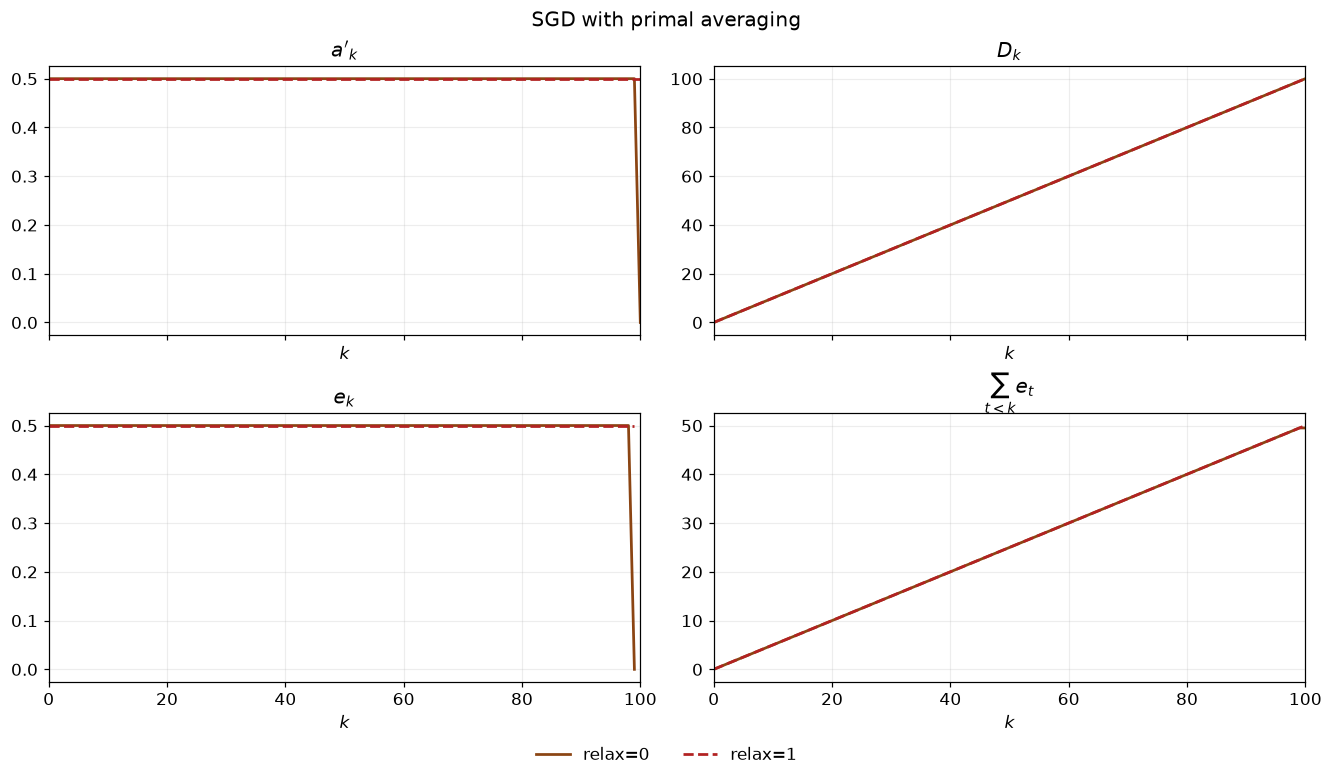

| 설정 | $D_N$ | $a'_N$ | $e_{N-1}$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/D_N$ |
| --- | --- | --- | --- | --- | --- |
| 0 | 100 | 0 | 1.35695e-07 | 49.5 | 0.495 |
| 1 | 100 | 0.5 | 0.5 | 50 | 0.5 |

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for relax, color, linestyle in ((0, "saddlebrown", "-"), (1, "firebrick", "--")):
    result = primal_results[relax]
    for ax, key, title in zip(axes.flat, ("ap", "d", "e", "ec"),
                               (r"$a'_k$", r"$D_k$", r"$e_k$", r"$\sum_{t<k}e_t$")):
        iterations = np.arange(N) if key == "e" else np.arange(N + 1)
        ax.plot(iterations, result[key], color=color, linestyle=linestyle,
                linewidth=1.8, label=f"relax={relax}")
        ax.set(title=title, xlim=(0, N), xlabel=r"$k$")
fig.suptitle("SGD with primal averaging")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()
headers = ["설정", r"$D_N$", r"$a'_N$", r"$e_{N-1}$", r"$\sum_{k=0}^{N-1}e_k$", r"$(\sum e_k)/D_N$"]
rows = [[relax, f"{r['d_N']:.6g}", f"{r['ap'][-1]:.6g}", f"{r['e'][-1]:.6g}",
         f"{r['sum_e']:.6g}", f"{r['sum_e'] / r['d_N']:.6g}"]
        for relax, r in primal_results.items()]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines = lines + ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

`relax=0`에서는 $a'_N=0$이고, 마지막 오차 계수 $e_{N-1}$도 수치적으로 거의 $0$이다. $y_N$은 마지막 oracle 호출 전에 정해진다. 따라서 최종 potential에 $x_N$의 거리항이 없으면, 마지막 확률적 갱신의 오차를 최종 potential의 변화에 반영할 필요가 없다.

반면 `relax=1`은 $a'_N=L/2$를 유지하므로 마지막 갱신의 분산이 거리항에 들어간다. 그 결과 $e_{N-1}\approx1/(2L)=0.5$가 남는다. 마지막 오차 계수의 차이는 이렇게 두 설정의 최종 potential 차이와 연결된다.

다음 정리는 거리항을 유지하는 `relax=1`과 같은 형태의 potential에 대해, 모든 단계에서 사용할 계수를 명시적으로 제시한다.


### 5단계 · 해석적 potential inequality와 수렴률

4단계에서 최종 거리항을 유지한 설정의 수치해를 보면, 오차 계수가 거의 일정했다. 이제 그 패턴을 $e_k=L\delta_k^2/2$라는 명시적 식으로 쓰고, 평균 갱신식이 왜 추가항 없이 potential inequality를 성립시키는지 증명한다.

#### Theorem 7의 명시적 계수

Theorem 7은 $0\le\delta_k\le1/L$에서

$$\phi_k^f=D_k(f(y_k)-f_\star)+\frac L2\|x_k-x_\star\|^2,\qquad
D_{k+1}=D_k+L\delta_k,\qquad e_k=\frac{L\delta_k^2}{2}$$

로 두면 $\mathbb E_i\phi_{k+1}^f\le\phi_k^f+e_k\sigma^2$가 성립함을 보장한다. 현재의 $\delta_k=1/L$, $D_0=0$에서는

$$D_k=k,\qquad e_k=\frac1{2L},\qquad
\sum_{k=0}^{N-1}e_k=\frac N{2L}$$

이다. 함수값 계수는 선형으로 증가하고, 단계별 오차 계수는 처음부터 일정하다.


In [31]:
analytical_primal = {
    "a": np.zeros(N + 1), "b": np.zeros(N + 1), "c": np.zeros(N + 1),
    "ap": np.full(N + 1, L / 2), "d": np.arange(N + 1, dtype=float),
    "e": np.full(N, 1 / (2 * L)),
}
analytical_primal["ec"] = np.r_[0., np.cumsum(analytical_primal["e"])]

최종 거리항을 동일하게 유지하는 `relax=1`의 수치 수열과 Theorem 7의 수열을 비교한다. Theorem 6의 $e_k$에 있던 추가항 $1/[2L(k+1)]$가 이번에는 없다. 아래 그림과 표에서 수치해의 오차 계수가 이 일정한 값과 얼마나 가까운지 확인한다.


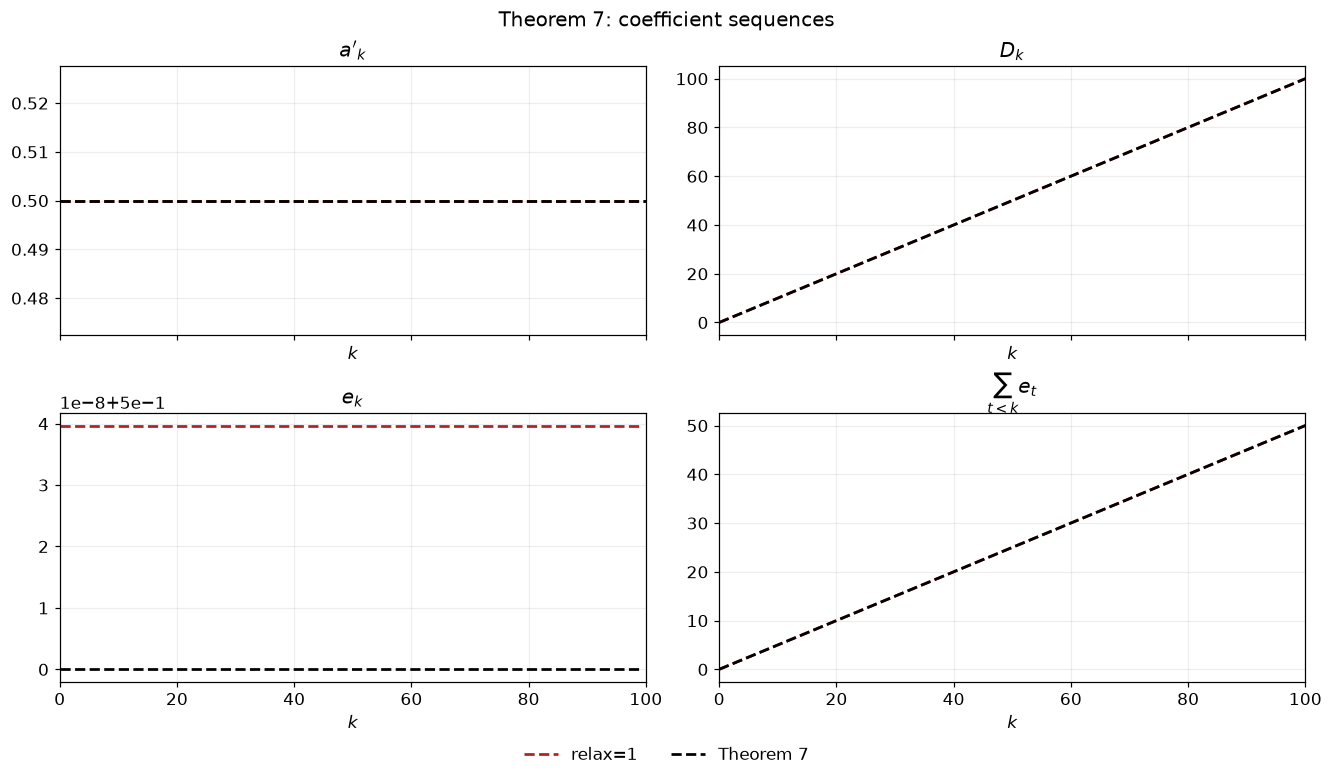

| 계수 | 수치해의 마지막 값 | Theorem 7의 마지막 값 | 수열의 최대 절댓값 차이 |
| --- | --- | --- | --- |
| $a'_k$ | 0.5 | 0.5 | 0.000e+00 |
| $D_k$ | 100 | 100 | 0.000e+00 |
| $e_k$ | 0.50000004 | 0.5 | 3.968e-08 |
| $\sum_{t=0}^{k-1}e_t$ | 50.000004 | 50 | 3.968e-06 |

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for result, label, color, linestyle in (
    (primal_results[1], "relax=1", "firebrick", "--"),
    (analytical_primal, "Theorem 7", "black", "--"),
):
    for ax, key, title in zip(axes.flat, ("ap", "d", "e", "ec"),
                               (r"$a'_k$", r"$D_k$", r"$e_k$", r"$\sum_{t<k}e_t$")):
        iterations = np.arange(N) if key == "e" else np.arange(N + 1)
        ax.plot(iterations, result[key], color=color, linestyle=linestyle, linewidth=1.8, label=label)
        ax.set(title=title, xlim=(0, N), xlabel=r"$k$")
fig.suptitle("Theorem 7: coefficient sequences")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()
coefficient_labels = {"ap": r"$a'_k$", "d": r"$D_k$", "e": r"$e_k$", "ec": r"$\sum_{t=0}^{k-1}e_t$"}
headers = ["계수", "수치해의 마지막 값", "Theorem 7의 마지막 값", "수열의 최대 절댓값 차이"]
rows = [[coefficient_labels[key], f"{primal_results[1][key][-1]:.8g}", f"{analytical_primal[key][-1]:.8g}",
         f"{np.max(np.abs(primal_results[1][key] - analytical_primal[key])):.3e}"]
        for key in ("ap", "d", "e", "ec")]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines = lines + ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

#### 명시적 multiplier로 LMI를 구성하기

$\delta_k=1/L$, $D_k=k$에서는 두 interpolation multiplier만 사용한다.

$$\lambda_{\star,y_{k+1}}=1,\qquad
\lambda_{y_k,y_{k+1}}=k.$$

나머지 multiplier는 모두 $0$으로 둔다. 실제 gradient를 나타내는 계수벡터를 그대로 사용하면, 남은 행렬은

$$R_k=-\frac{k}{2L}
(\mathbf g_{y_{k+1}}-\mathbf g_{y_k})
(\mathbf g_{y_{k+1}}-\mathbf g_{y_k})^\top\preceq0$$

이다. 함수값 계수도

$$\begin{aligned}
r_k={}&-k\mathbf f_{y_k}+(k+1)\mathbf f_{y_{k+1}}
-\mathbf f_{y_{k+1}}
+k(\mathbf f_{y_k}-\mathbf f_{y_{k+1}})=0
\end{aligned}$$

으로 소거된다. 아래에서는 이 계수를 원래의 $5\times5$ LMI에 대입한다. 이어지는 증명에서는 평균 갱신식이 이러한 소거를 가능하게 하는 이유를 확인한다.


In [33]:
R_primal, equality_primal, expected_primal, weights_primal = [], [], [], []
for k in range(1, N + 1):
    d_current = analytical_primal["d"][k - 1]
    X = {1: xs, 2: yk, 3: yk1(d_current, k)}
    G = {1: gxs, 2: gyk, 3: gyk1}
    F = {1: fxs, 2: fyk, 3: fyk1}
    weights = np.zeros((nbPts, nbPts))
    weights[0, 2] = 1
    weights[1, 2] = k - 1
    R = -L / 2 * np.outer(xk - xs, xk - xs) - analytical_primal["e"][k - 1] * Avar
    equality = -d_current * fyk + analytical_primal["d"][k] * fyk1
    XK1 = xk1(k)
    for i in range(1, n + 1):
        R = R + L / (2 * n) * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs)
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if j != i:
                TT = np.vstack((X[i], X[j], G[i], G[j]))
                R = R + weights[i - 1, j - 1] * (TT.T @ M @ TT)
                equality = equality + weights[i - 1, j - 1] * (F[i] - F[j])
    R_primal.append(R)
    equality_primal.append(equality)
    weights_primal.append(weights)
    expected_primal.append(-(k - 1) / (2 * L) * np.outer(gyk1 - gyk, gyk1 - gyk))

In [34]:
check_primal = {
    "R": np.asarray(R_primal), "equality": np.asarray(equality_primal),
    "lmi_violation": float(max(0., np.linalg.eigvalsh(R_primal).max())),
    "equality_violation": float(np.max(np.abs(equality_primal))),
    "multiplier_violation": float(max(0., -np.min(weights_primal))),
    "matrix_identity_error": float(np.max(np.abs(np.asarray(R_primal) - expected_primal))),
}

print(f"Theorem 7: matrix identity error={check_primal['matrix_identity_error']:.3e}")


Theorem 7: matrix identity error=1.138e-15


#### Appendix E.3 — 평균 갱신식이 교차항을 소거하는 과정

현재 상태를 고정한 조건부 기대값을 $\mathbb E_i$로 쓴다. 평균점 $y_{k+1}$은 oracle 호출 전에 정해지며,

$$(D_k+L\delta_k)y_{k+1}=D_ky_k+L\delta_kx_k$$

를 만족한다. Interpolation 부등식 $\mathcal I_{\star,y_{k+1}}$,
$\mathcal I_{y_k,y_{k+1}}$에 각각 $L\delta_k,D_k$를 곱하면, 내적항은

$$\begin{aligned}
&L\delta_k
\langle\nabla f(y_{k+1}),y_{k+1}-x_\star\rangle
-D_k\langle\nabla f(y_{k+1}),y_k-y_{k+1}\rangle\\
&=L\delta_k\langle\nabla f(y_{k+1}),x_k-x_\star\rangle
\end{aligned}$$

로 모인다. 한편 SGD 갱신식에서 거리항을 전개하고 unbiasedness를 사용하면

$$\begin{aligned}
&\frac L2\left(
\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2-\|x_k-x_\star\|^2
\right)\\
&=-L\delta_k\langle\nabla f(y_{k+1}),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(y_{k+1};i)\|^2.
\end{aligned}$$

두 식을 더하면 위치와 gradient 사이의 내적이 소거된다. Oracle 출력의 norm 제곱항에는

$$\mathbb E_i\|G(y_{k+1};i)\|^2
=\|\nabla f(y_{k+1})\|^2
+\mathbb E_i\|G(y_{k+1};i)-\nabla f(y_{k+1})\|^2$$

를 사용한다. 함수값 항은 $D_{k+1}=D_k+L\delta_k$에 의해 다음·현재 potential의 차이로 정리된다. 이들을 합하면

$$\begin{aligned}
&\mathbb E_i\phi_{k+1}^f-\phi_k^f
-\frac{L\delta_k^2}{2}
\mathbb E_i\|G(y_{k+1};i)-\nabla f(y_{k+1})\|^2\\
&\qquad+L\delta_k\mathcal I_{\star,y_{k+1}}
+D_k\mathcal I_{y_k,y_{k+1}}\\
&=-\frac{\delta_k}{2}(1-L\delta_k)
\|\nabla f(y_{k+1})\|^2
-\frac{D_k}{2L}
\|\nabla f(y_{k+1})-\nabla f(y_k)\|^2
\le0.
\end{aligned}$$

$D_k\ge0$, $0\le\delta_k\le1/L$이면 마지막 두 항은 모두 0 이하다. Interpolation 항들은 비음수이고 oracle의 분산은 $\sigma^2$ 이하이므로

$$\mathbb E_i\phi_{k+1}^f-\phi_k^f
\le\frac{L\delta_k^2}{2}
\mathbb E_i\|G(y_{k+1};i)-\nabla f(y_{k+1})\|^2
\le\frac{L\delta_k^2}{2}\sigma^2.$$

따라서 $e_k=L\delta_k^2/2$이면 충분하다. 평균점을 oracle 평가점으로 사용한 덕분에, Theorem 6에서 필요했던 추가항 없이 교차항을 정리할 수 있었다.

$\delta_k=1/L$, $D_0=0$이면 $y_N=N^{-1}\sum_{t=0}^{N-1}x_t$이다. 한 단계 부등식에 전체 기대값을 취해 합하면

$$N\mathbb E[f(y_N)-f_\star]
+\frac L2\mathbb E\|x_N-x_\star\|^2
\le\frac L2\|x_0-x_\star\|^2+\frac N{2L}\sigma^2$$

를 얻는다. 따라서 최종 함수값 상한은

$$\boxed{\mathbb E[f(y_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2N}+\frac{\sigma^2}{2L}}$$

이다.


## 종합 비교 · Table 2

두 평균법 모두 공통 파이프라인의 5단계까지 마쳐, 모든 단계에서 성립하는 명시적 potential inequality와 함수값 상한을 얻었다. 이제 앞선 SGD의 Theorem 5와 이번 Theorem 6·7을 같은 step-size 규칙 아래에서 비교한다.

이하의 계산 대상은 **앞서 증명한 부등식에 사용한 명시적 계수 수열의 합**이다. 새로운 SDP를 구성하거나 potential 계수를 다시 탐색하지 않고, $D_N$과 $\sum e_k$를 계산해 최종 상한을 비교한다. 먼저 고정 step-size에서 차이를 확인한 뒤, 감소 step-size와 Table 2의 지수 선택으로 연결한다.

### 고정 step-size에서 세 방법을 비교하기

$\delta_k=1/L$, $D_0=0$이면 세 정리 모두 $D_N=N$이다. 이제 최종 상한에서 초기 거리와 분산이 각각 어떤 계수로 들어가는지 비교하자.

$$R^2=\|x_0-x_\star\|^2,\qquad
A_N=\frac{L}{2N},\qquad
B_N=\frac{\sum_{k=0}^{N-1}e_k}{N}$$

로 두면, 각 방법의 출력 $v_N=x_N,z_N,y_N$에 대해

$$\mathbb E[f(v_N)-f_\star]\le A_NR^2+B_N\sigma^2$$

로 쓸 수 있다. $A_N$은 초기 거리 제곱에 곱해지는 계수이고, $B_N$은 oracle 분산에 곱해지는 계수다. $H_N=\sum_{j=1}^N j^{-1}$를 사용해 세 방법의 오차 계수를 정리하면 다음과 같다.

| 방법 | $e_k$ | $\sum_{k<N}e_k$ | $B_N=(\sum_{k<N}e_k)/N$ |
| --- | --- | --- | --- |
| SGD, Theorem 5 | $(k+2)/(2L)$ | $N(N+3)/(4L)$ | $(N+3)/(4L)$ |
| Averaging, Theorem 6 | $(1+1/(k+1))/(2L)$ | $(N+H_N)/(2L)$ | $(1+H_N/N)/(2L)$ |
| Primal averaging, Theorem 7 | $1/(2L)$ | $N/(2L)$ | $1/(2L)$ |

초기 거리에서 오는 항 $A_NR^2=LR^2/(2N)$은 공통이다. 따라서 이 비교에서 방법 사이의 차이를 만드는 것은 $B_N$이다.


In [35]:
transitions = np.arange(N_FIGURE)
constant_results = {
    "SGD / Theorem 5": {"e": (transitions + 2) / (2 * L)},
    "Averaging / Theorem 6": analytical_avg,
    "Primal / Theorem 7": analytical_primal,
}
constant_results["SGD / Theorem 5"]["ec"] = np.r_[
    0., np.cumsum(constant_results["SGD / Theorem 5"]["e"])]
constant_colors = {
    "SGD / Theorem 5": "saddlebrown",
    "Averaging / Theorem 6": "royalblue",
    "Primal / Theorem 7": "purple",
}
H_N = np.sum(1 / np.arange(1, N_FIGURE + 1))
closed_sums = [N_FIGURE * (N_FIGURE + 3) / (4 * L),
               (N_FIGURE + H_N) / (2 * L), N_FIGURE / (2 * L)]
headers = ["방법", r"$\sum e_k$", "명시적 합", r"$B_N$", r"$A_N$"]
rows = [(label, f"{r['ec'][-1]:.8g}", f"{closed:.8g}",
         f"{r['ec'][-1] / N_FIGURE:.8g}", f"{L / (2 * N_FIGURE):.8g}")
        for (label, r), closed in zip(constant_results.items(), closed_sums)]
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | $\sum e_k$ | 명시적 합 | $B_N$ | $A_N$ |
| --- | --- | --- | --- | --- |
| SGD / Theorem 5 | 2575 | 2575 | 25.75 | 0.005 |
| Averaging / Theorem 6 | 52.593689 | 52.593689 | 0.52593689 | 0.005 |
| Primal / Theorem 7 | 50 | 50 | 0.5 | 0.005 |

다음 세 패널은 단계별 오차 계수 $e_k$, 누적합 $\sum_{k<N}e_k$, 최종 분산 계수 $B_N$을 차례로 보여 준다. SGD에서는 $B_N=\Theta(N)$이고, 두 평균법에서는 $B_N\to1/(2L)$이다. 먼저 전체 그림에서 SGD와 두 평균법의 차이를 확인한 뒤, 두 평균법만 확대해 그 사이에 남은 차이를 살펴본다.


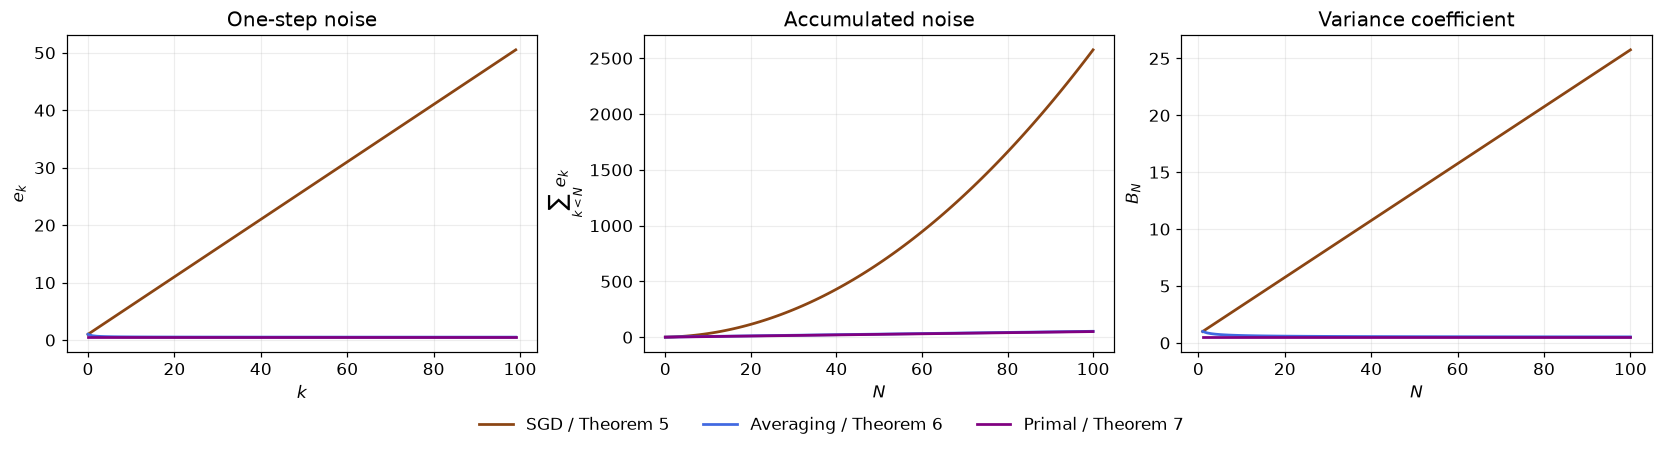

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for label, r in constant_results.items():
    axes[0].plot(np.arange(N_FIGURE), r["e"], color=constant_colors[label],
                 linewidth=1.8, label=label)
    axes[1].plot(np.arange(N_FIGURE + 1), r["ec"], color=constant_colors[label],
                 linewidth=1.8, label=label)
    axes[2].plot(np.arange(1, N_FIGURE + 1),
                 r["ec"][1:] / np.arange(1, N_FIGURE + 1),
                 color=constant_colors[label], linewidth=1.8, label=label)
axes[0].set(xlabel=r"$k$", ylabel=r"$e_k$", title="One-step noise")
axes[1].set(xlabel=r"$N$", ylabel=r"$\sum_{k<N}e_k$",
            title="Accumulated noise")
axes[2].set(xlabel=r"$N$", ylabel=r"$B_N$",
            title="Variance coefficient")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

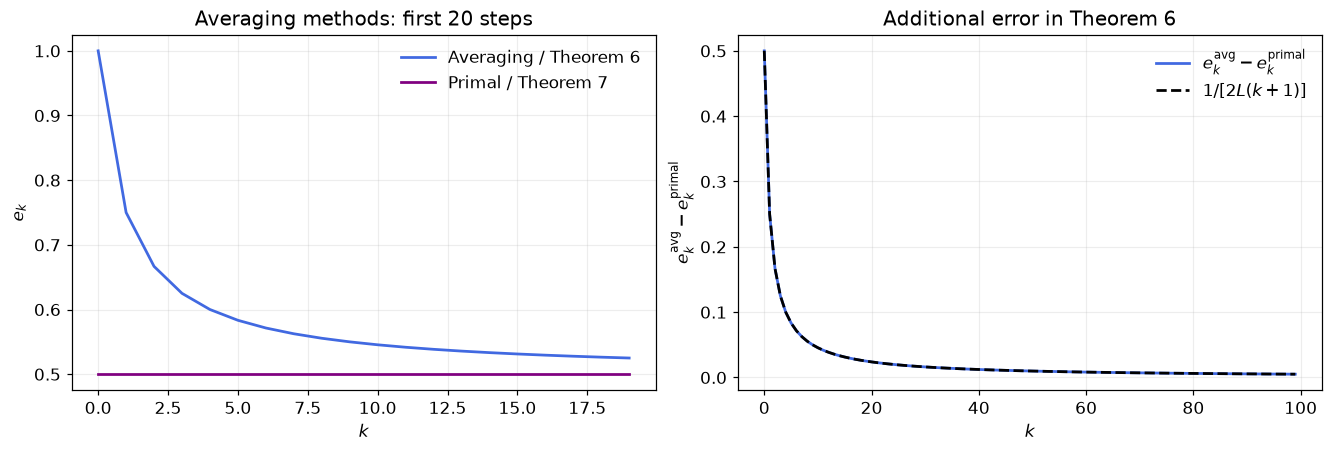

In [37]:
zoom_end = min(20, N_FIGURE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for label in ("Averaging / Theorem 6", "Primal / Theorem 7"):
    result = constant_results[label]
    axes[0].plot(np.arange(zoom_end), result["e"][:zoom_end],
                 color=constant_colors[label], linewidth=1.8, label=label)
difference = analytical_avg["e"] - analytical_primal["e"]
axes[1].plot(transitions, difference, color="royalblue", linewidth=1.8,
             label=r"$e_k^{\mathrm{avg}}-e_k^{\mathrm{primal}}$")
axes[1].plot(transitions, 1 / (2 * L * (transitions + 1)),
             color="black", linestyle="--", linewidth=1.8,
             label=r"$1/[2L(k+1)]$")
axes[0].set(xlabel=r"$k$", ylabel=r"$e_k$", title="Averaging methods: first 20 steps")
axes[1].set(xlabel=r"$k$", ylabel=r"$e_k^{\mathrm{avg}}-e_k^{\mathrm{primal}}$",
            title="Additional error in Theorem 6")
for ax in axes:
    ax.legend(frameon=False)
plt.show()


두 평균법의 단계별 오차 계수 차이는

$$e_k^{\mathrm{avg}}-e_k^{\mathrm{primal}}
=\frac1{2L(k+1)}$$

이다. Averaging은 SGD에서 나타난 오차 계수의 증가를 억제하고, primal averaging은 남아 있던 이 추가항도 없앤다. 다만 고정 step-size에서 두 방법의 분산 계수 $B_N$은 0으로 가지 않는다. 분산의 상한이 $\sigma^2>0$일 때 함수값 상한이 0에 수렴하도록 하려면, step-size를 줄이면서 함수값 계수와 오차 계수의 누적합이 증가하는 속도를 함께 조절해야 한다.


### 감소 step-size와 Appendix E.5의 가중평균

고정 step-size에서는 두 평균법의 분산 계수도 0으로 가지 않았다. 앞서 증명한 한 단계 부등식은 가변 step-size도 허용하므로, 이번에는 감소하는 step-size를 명시적 계수에 대입해 합한다. 특히 Theorem 6에서는 단계 사이의 함수값 계수가 이어지도록 평균 가중치를 조정해야 한다.

이제 세 방법에 같은 step-size 규칙을 적용한다.

$$\delta_k=\frac1{L(k+1)^\alpha},\qquad
q_k=L\delta_k=(k+1)^{-\alpha},\qquad
D_0=0,\quad D_{k+1}=D_k+q_k.$$

여기서 $q_k$는 $L\delta_k$를 짧게 쓴 값이다. Theorem 6에서는 한 단계의 현재 함수값 계수가 평균 가중치에 $q_k$를 곱한 값이었다. 여러 단계의 계수가 정확히 이어지도록 평균 가중치를 $m_k=D_k/q_k$로 선택하면

$$q_km_k=D_k,\qquad q_k(m_k+1)=D_{k+1},\qquad
m_{k+1}=\frac{\delta_k}{\delta_{k+1}}(m_k+1)$$

이 된다. 따라서 Appendix E.5의 평균 갱신식은

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
z_{k+1}^{(i)}
=\frac{D_kz_k+q_kx_{k+1}^{(i)}}{D_{k+1}},\qquad
z_N=\frac{\sum_{k<N}\delta_kx_{k+1}}{\sum_{k<N}\delta_k}$$

이다. 즉, 새 반복점에 step-size에 비례하는 가중치를 주는 평균이다. $\alpha=0$에서는 앞서 사용한 산술평균과 일치한다.

A의 SGD with averaging에 대한 SDP 실험은 1부터 시작하는 인덱스의 `delta(i)`와 산술평균을 사용했다. 지금부터 계산하는 계수합은 위의 $k=0$부터 시작하는 $\delta_k$와 Appendix E.5의 step-size 가중평균에 해당한다. 감소 step-size에서도 같은 potential 부등식을 단계마다 연결하기 위한 구성이다.


In [38]:
N_RATE = 100_000
Ns = np.unique(np.geomspace(10, N_RATE, 70).astype(int))
alphas = (0.0, 0.5, 2 / 3, 0.8)
methods = ("sgd", "averaging", "primal")
method_labels = {
    "sgd": "SGD / Theorem 5",
    "averaging": "Weighted averaging / Theorem 6",
    "primal": "Primal averaging / Theorem 7",
}
method_colors = {"sgd": "saddlebrown", "averaging": "royalblue", "primal": "purple"}

세 정리의 오차 계수를 공통 함수값 계수 $D_k$로 쓰면 다음과 같다.

$$\begin{aligned}
e_k^{\mathrm{SGD}}
&=\frac{L\delta_k^2}{2}(1+D_{k+1}),\\
e_k^{\mathrm{avg}}
&=\frac{L\delta_k^2}{2}
\left(1+\frac{q_k}{m_k+1}\right)
=\frac{L\delta_k^2}{2}
\left(1+\frac{q_k^2}{D_{k+1}}\right),\\
e_k^{\mathrm{primal}}
&=\frac{L\delta_k^2}{2}.
\end{aligned}$$

두 평균법 모두 새 점에 주는 가중치는 $q_k/D_{k+1}$이다. 그러나 averaging은 SGD 갱신 후의 점을 평균에 넣고, primal averaging은 갱신 전의 점으로 평균을 만든 뒤 그 평균점에서 oracle을 평가한다. 아래 코드는 각 $\alpha$에 대해 이 정리들의 계수 수열과 누적합을 계산한다.


In [39]:
rate_results = {}
for alpha in alphas:
    delta_state = 1 / (L * (np.arange(N_RATE + 1, dtype=float) + 1)**alpha)
    delta = delta_state[:-1]
    q = L * delta
    d = np.r_[0., np.cumsum(q)]
    step_errors = {
        "sgd": L * delta**2 * (1 + d[1:]) / 2,
        "averaging": L * delta**2 * (1 + q**2 / d[1:]) / 2,
        "primal": L * delta**2 / 2,
    }
    for method in methods:
        e = step_errors[method]
        m = d / (L * delta_state) if method == "averaging" else d.copy()
        new_weight = np.ones(N_RATE) if method == "sgd" else q / d[1:]
        rate_results[method, alpha] = {
            "method": method, "N": N_RATE, "L": L, "alpha": alpha,
            "delta": delta, "d": d, "m": m, "e": e,
            "ec": np.r_[0., np.cumsum(e)], "new_weight": new_weight,
        }

한 단계 부등식을 합하면 각 방법의 출력 $v_N=x_N,z_N,y_N$에 대해

$$\mathbb E[f(v_N)-f_\star]\le A_NR^2+B_N\sigma^2,\qquad
A_N=\frac{L}{2D_N},\quad
B_N=\frac{\sum_{k<N}e_k}{D_N}$$

를 얻는다. 앞과 같이 $R^2=\|x_0-x_\star\|^2$이다. 이번에는 $D_N$이 step-size에 따라 달라지므로, 분모에도 그 변화를 반영한다.

아래 그림은 $R^2=\sigma^2=1$로 놓고 위쪽에 분산 계수 $B_N$, 아래쪽에 전체 상한 $A_N+B_N$을 표시한다. 이는 세 정리에서 얻은 상한의 비교다. Step-size를 빠르게 줄이면 오차 계수의 누적합은 작아지지만 함수값 계수의 증가도 느려지므로, 두 효과를 함께 살펴보자.


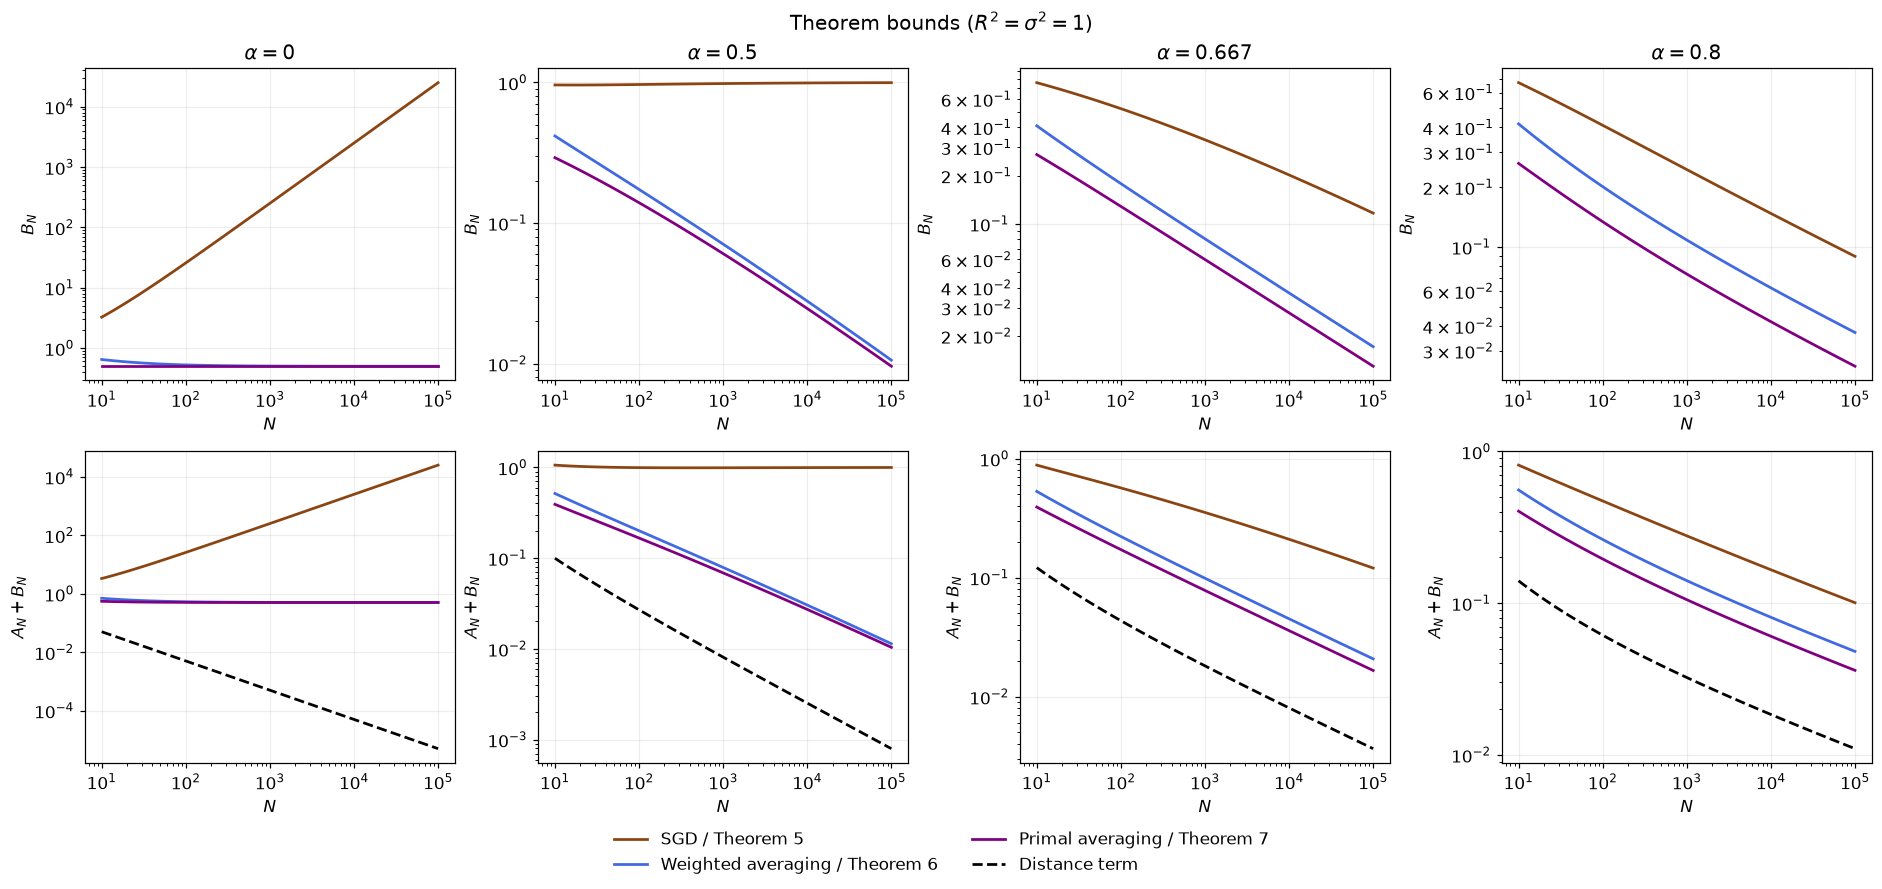

In [40]:
for r in rate_results.values():
    r["bound_distance"] = np.r_[np.nan, L / (2 * r["d"][1:])]
    r["bound_variance"] = np.r_[np.nan, r["ec"][1:] / r["d"][1:]]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), layout="constrained")
for column, alpha in enumerate(alphas):
    for method in methods:
        r = rate_results[method, alpha]
        axes[0, column].loglog(Ns, r["bound_variance"][Ns],
                              color=method_colors[method], linewidth=1.8,
                              label=method_labels[method])
        axes[1, column].loglog(Ns,
                              r["bound_distance"][Ns] + r["bound_variance"][Ns],
                              color=method_colors[method], linewidth=1.8,
                              label=method_labels[method])
    axes[1, column].loglog(Ns, rate_results["sgd", alpha]["bound_distance"][Ns],
                          color="black", linestyle="--", linewidth=1.8,
                          label="Distance term")
    axes[0, column].set(title=rf"$\alpha={alpha:.3g}$",
                        xlabel=r"$N$", ylabel=r"$B_N$")
    axes[1, column].set(xlabel=r"$N$", ylabel=r"$A_N+B_N$")
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(r"Theorem bounds ($R^2=\sigma^2=1$)")
plt.show()

분산 계수의 감소 속도를 수치로 확인하기 위해, 사용한 반복 횟수 $N$ 가운데 가장 큰 8개에서 log–log 기울기를 추정한다.

$$\log B_N\approx a+s\log N,\qquad
(s,a)=\operatorname{polyfit}(\log N,\log B_N,1).$$

$B_N$이 $N^{-p}$에 비례한다면 기울기는 $-p$에 가까워진다. 다음 표의 기울기를 구간별 수식과 비교하고, 임계점에서는 로그 인자가 관측 기울기에 어떤 차이를 만드는지 이어서 살펴본다.


In [41]:
headers = [r"$\alpha$", "방법", r"$D_N$", r"$A_N$", r"$B_N$",
           r"$A_N+B_N$", r"$B_N$의 log–log 기울기"]
rows = []
for (method, alpha), r in rate_results.items():
    slope, intercept = np.polyfit(np.log(Ns[-8:]),
                                 np.log(r["bound_variance"][Ns[-8:]]), 1)
    rows.append((f"{alpha:.4g}", method_labels[method], f"{r['d'][-1]:.6g}",
                 f"{r['bound_distance'][-1]:.6g}",
                 f"{r['bound_variance'][-1]:.6g}",
                 f"{r['bound_distance'][-1] + r['bound_variance'][-1]:.6g}",
                 f"{slope:.4f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| $\alpha$ | 방법 | $D_N$ | $A_N$ | $B_N$ | $A_N+B_N$ | $B_N$의 log–log 기울기 |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | SGD / Theorem 5 | 100000 | 5e-06 | 25000.8 | 25000.8 | 1.0000 |
| 0 | Weighted averaging / Theorem 6 | 100000 | 5e-06 | 0.50006 | 0.500065 | -0.0002 |
| 0 | Primal averaging / Theorem 7 | 100000 | 5e-06 | 0.5 | 0.500005 | -0.0000 |
| 0.5 | SGD / Theorem 5 | 630.997 | 0.000792397 | 0.99658 | 0.997372 | 0.0016 |
| 0.5 | Weighted averaging / Theorem 6 | 630.997 | 0.000792397 | 0.0105805 | 0.0113729 | -0.4238 |
| 0.5 | Primal averaging / Theorem 7 | 630.997 | 0.000792397 | 0.0095802 | 0.0103726 | -0.4154 |
| 0.6667 | SGD / Theorem 5 | 136.8 | 0.00365496 | 0.116631 | 0.120286 | -0.2432 |
| 0.6667 | Weighted averaging / Theorem 6 | 136.8 | 0.00365496 | 0.0171115 | 0.0207665 | -0.3349 |
| 0.6667 | Primal averaging / Theorem 7 | 136.8 | 0.00365496 | 0.0129251 | 0.01658 | -0.3332 |
| 0.8 | SGD / Theorem 5 | 45.5625 | 0.0109739 | 0.0896698 | 0.100644 | -0.2148 |
| 0.8 | Weighted averaging / Theorem 6 | 45.5625 | 0.0109739 | 0.0370779 | 0.0480518 | -0.2212 |
| 0.8 | Primal averaging / Theorem 7 | 45.5625 | 0.0109739 | 0.0250656 | 0.0360395 | -0.2210 |

### Table 2 — 거듭제곱 차수와 로그 인자를 구분하기

Table 2는 초기 거리에서 오는 항과 분산에서 오는 항을 비교한다. 아래 표의 분산 항의 차수는 SGD에서 $0\le\alpha<2/3$, 두 평균법에서 $0\le\alpha<1/2$인 구간에 해당한다. 균형점에서는 $\log N$ 인자가 추가되며, 그보다 큰 $\alpha$에서는 뒤에서 정리할 구간별 식을 적용해야 한다.

| 방법 | 초기 거리 항 | 분산 항 | 균형점 $\alpha$ |
| --- | --- | --- | --- |
| SGD | $O(N^{\alpha-1})$ | $O(N^{1-2\alpha})$ | $2/3$ |
| Averaging | $O(N^{\alpha-1})$ | $O(N^{-\alpha})$ | $1/2$ |
| Primal averaging | $O(N^{\alpha-1})$ | $O(N^{-\alpha})$ | $1/2$ |

이 차수는 다음의 정확한 유한 합에서 얻는다.

$$\begin{aligned}
D_N&=\sum_{k<N}q_k,\\
\sum_{k<N}e_k^{\mathrm{SGD}}
&=\frac1{2L}\sum_{k<N}q_k^2(1+D_{k+1}),\\
\sum_{k<N}e_k^{\mathrm{avg}}
&=\frac1{2L}\left(
\sum_{k<N}q_k^2+\sum_{k<N}\frac{q_k^4}{D_{k+1}}
\right),\\
\sum_{k<N}e_k^{\mathrm{primal}}
&=\frac1{2L}\sum_{k<N}q_k^2,\qquad
B_N=\frac{\sum_{k<N}e_k}{D_N}.
\end{aligned}$$

아래에서는 이 식으로 오차 계수의 누적합을 직접 계산한다. 같은 $D_N$으로 나누었을 때, 세 방법의 분산 계수 차이가 어떤 합에서 생기는지 확인할 수 있다.


In [42]:
headers = [r"$\alpha$", "방법", r"$D_N$", r"$\sum_{k<N}e_k$", r"$(\sum_{k<N}e_k)/D_N$"]
rows = []
for alpha in alphas:
    q = (np.arange(1, N_RATE + 1, dtype=float))**(-alpha)
    d_next = np.cumsum(q)
    noise_sums = {
        "sgd": np.sum(q**2 * (1 + d_next)) / (2 * L),
        "averaging": (np.sum(q**2) + np.sum(q**4 / d_next)) / (2 * L),
        "primal": np.sum(q**2) / (2 * L),
    }
    for method in methods:
        rows.append((f"{alpha:.4g}", method_labels[method], f"{d_next[-1]:.6g}",
                     f"{noise_sums[method]:.6g}",
                     f"{noise_sums[method] / d_next[-1]:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| $\alpha$ | 방법 | $D_N$ | $\sum_{k<N}e_k$ | $(\sum_{k<N}e_k)/D_N$ |
| --- | --- | --- | --- | --- |
| 0 | SGD / Theorem 5 | 100000 | 2.50008e+09 | 25000.8 |
| 0 | Weighted averaging / Theorem 6 | 100000 | 50006 | 0.50006 |
| 0 | Primal averaging / Theorem 7 | 100000 | 50000 | 0.5 |
| 0.5 | SGD / Theorem 5 | 630.997 | 628.839 | 0.99658 |
| 0.5 | Weighted averaging / Theorem 6 | 630.997 | 6.67628 | 0.0105805 |
| 0.5 | Primal averaging / Theorem 7 | 630.997 | 6.04507 | 0.0095802 |
| 0.6667 | SGD / Theorem 5 | 136.8 | 15.9552 | 0.116631 |
| 0.6667 | Weighted averaging / Theorem 6 | 136.8 | 2.34086 | 0.0171115 |
| 0.6667 | Primal averaging / Theorem 7 | 136.8 | 1.76815 | 0.0129251 |
| 0.8 | SGD / Theorem 5 | 45.5625 | 4.08558 | 0.0896698 |
| 0.8 | Weighted averaging / Theorem 6 | 45.5625 | 1.68936 | 0.0370779 |
| 0.8 | Primal averaging / Theorem 7 | 45.5625 | 1.14205 | 0.0250656 |

$0\le\alpha<1$에서는 $D_{k+1}\asymp(k+1)^{1-\alpha}$이므로

$$A_N\asymp N^{\alpha-1},\qquad
\sum_{k<N}q_k^2D_{k+1}
\asymp\sum_{k<N}(k+1)^{1-3\alpha},\qquad
\sum_{k<N}q_k^2=\sum_{k<N}(k+1)^{-2\alpha}.$$

따라서 각 정리의 함수값 상한에 들어가는 분산 계수는 다음처럼 구간별로 나뉜다.

$$B_N^{\mathrm{SGD}}\asymp
\begin{cases}
N^{1-2\alpha},&0\le\alpha<2/3,\\
(\log N)N^{-1/3},&\alpha=2/3,\\
N^{\alpha-1},&2/3<\alpha<1,
\end{cases}$$

$$B_N^{\mathrm{avg}},\ B_N^{\mathrm{primal}}\asymp
\begin{cases}
N^{-\alpha},&0\le\alpha<1/2,\\
(\log N)N^{-1/2},&\alpha=1/2,\\
N^{\alpha-1},&1/2<\alpha<1.
\end{cases}$$

두 평균법의 차이를 만드는 추가합은
$\sum_{k<N}q_k^4/D_{k+1}\asymp\sum_{k<N}(k+1)^{-1-3\alpha}$이다.
$\alpha>0$이면 이 합은 유계이고, $\alpha=0$에서는 조화수 $H_N$이 된다. 추가항의 크기는 달라도, 두 평균법의 분산 계수는 위와 같이 점근적 차수가 같다.

앞 실험의 $\alpha=0.8$에서는 세 방법 모두 분산 계수가 $N^{-0.2}$ 차수다. Step-size를 더 빠르게 줄이면 오차 계수의 누적합은 작아지지만, $D_N$의 증가가 느려져 상한의 감소도 느려진다. 경계인 $\alpha=1$에서는 세 방법의 $A_N,B_N$이 모두 $\Theta(1/\log N)$이고, $\alpha>1$에서는 $\Theta(1)$이다.


임계점에서는 $B_N\asymp(\log N)N^{-p}$이다. 로그 인자의 영향을 보기 위해 다음 그림에서 $N^pB_N$과 $N^pB_N/\log N$을 나란히 비교한다. 거듭제곱만 제거하면 $\log N$에 따른 증가가 남고, 로그 인자로 한 번 더 나누면 상수에 가까워지는 모습을 기대할 수 있다.

$$\begin{array}{c|cc}
\text{방법}&\alpha&p\\\hline
\mathrm{SGD}&2/3&1/3\\
\text{Averaging, Primal averaging}&1/2&1/2
\end{array}$$


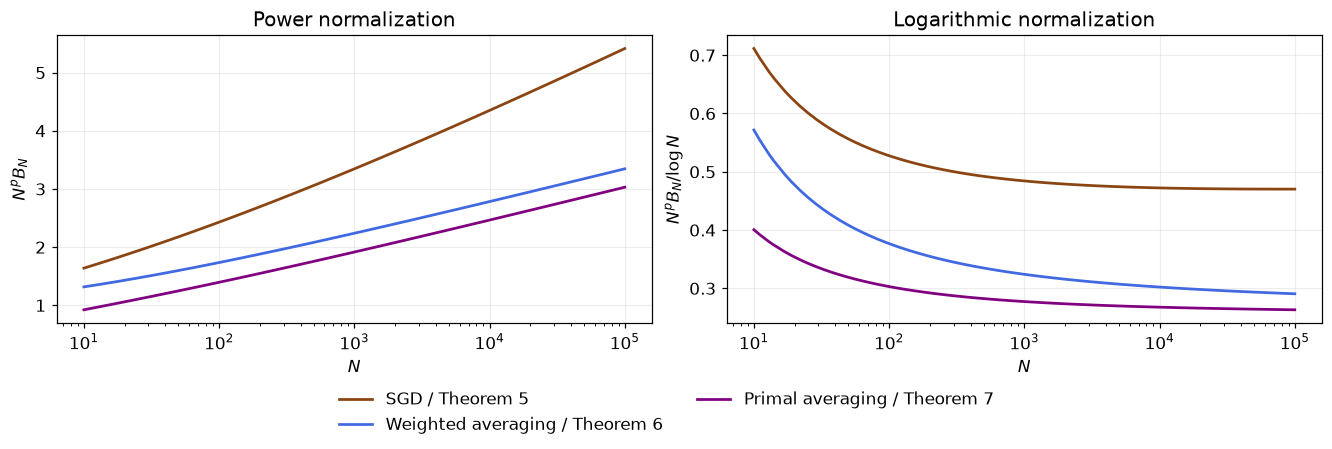

In [43]:
critical = {"sgd": 2 / 3, "averaging": 0.5, "primal": 0.5}
power = {"sgd": 1 / 3, "averaging": 0.5, "primal": 0.5}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for method in methods:
    r = rate_results[method, critical[method]]
    scaled = r["bound_variance"][Ns] * Ns**power[method]
    axes[0].semilogx(Ns, scaled, color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
    axes[1].semilogx(Ns, scaled / np.log(Ns), color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
axes[0].set(xlabel=r"$N$", ylabel=r"$N^pB_N$",
            title="Power normalization")
axes[1].set(xlabel=r"$N$", ylabel=r"$N^pB_N/\log N$",
            title="Logarithmic normalization")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()

임계점에서 $\log B_N\simeq C-p\log N+\log\log N$으로 쓰면, log–log 기울기는 큰 $N$에서 대략 $-p+1/\log N$이다. 따라서 유한 구간에서 측정한 기울기는 $-p$보다 크며, $N$이 커져도 천천히 $-p$에 접근한다. 다음 표는 이 기울기와 로그 인자로 나눈 $N^pB_N/\log N$을 함께 보여 준다.


In [44]:
headers = ["방법", r"$\alpha$", r"$p$", "log–log 기울기", r"$N^pB_N/\log N$"]
rows = []
for method in methods:
    variance = rate_results[method, critical[method]]["bound_variance"]
    slope, intercept = np.polyfit(np.log(Ns[-8:]), np.log(variance[Ns[-8:]]), 1)
    normalized = N_RATE**power[method] * variance[-1] / np.log(N_RATE)
    rows.append((method_labels[method], f"{critical[method]:.6g}", f"{power[method]:.6g}",
                 f"{slope:.5f}", f"{normalized:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | $\alpha$ | $p$ | log–log 기울기 | $N^pB_N/\log N$ |
| --- | --- | --- | --- | --- |
| SGD / Theorem 5 | 0.666667 | 0.333333 | -0.24321 | 0.470213 |
| Weighted averaging / Theorem 6 | 0.5 | 0.5 | -0.42384 | 0.290617 |
| Primal averaging / Theorem 7 | 0.5 | 0.5 | -0.41540 | 0.263141 |

### 두 항의 균형으로 step-size 지수를 선택하기

$0\le\alpha<1$에서 로그 인자를 제외한 전체 상한의 거듭제곱 차수를 $N^{-p(\alpha)}$로 쓰자. 초기 거리 항과 분산 항 중에서 점근적으로 더 큰 항이 전체 차수를 결정하므로

$$p_{\mathrm{SGD}}(\alpha)
=\min\{1-\alpha,\ 2\alpha-1\},\qquad
p_{\mathrm{avg}}(\alpha)=p_{\mathrm{primal}}(\alpha)
=\min\{1-\alpha,\alpha\}.$$

두 항의 지수를 같게 만드는 점에서는

$$1-\alpha=2\alpha-1
\quad\Longrightarrow\quad(\alpha,p)=(2/3,1/3),$$
$$1-\alpha=\alpha
\quad\Longrightarrow\quad(\alpha,p)=(1/2,1/2)$$

을 얻는다. 이것이 Table 2의 $\alpha=2/3$과 $\alpha=1/2$이며, 로그 인자를 생략하면 보장되는 수렴률은 각각 $\widetilde O(N^{-1/3})$, $\widetilde O(N^{-1/2})$이다.

주어진 $N$에서 유한 합으로 계산한 상한을 최소화하는 $\alpha$는 누적합의 상수와 $R^2,\sigma^2$에도 의존한다. 아래에서는 $N=10^5$, $R^2=\sigma^2=1$로 놓고, 점근적인 지수의 균형과 유한 합의 최솟값을 함께 비교한다.


In [45]:
alpha_grid = np.linspace(0., 0.95, 96)
polynomial_sgd = np.minimum(1 - alpha_grid, 2 * alpha_grid - 1)
polynomial_avg = np.minimum(1 - alpha_grid, alpha_grid)
finite_bounds = {method: [] for method in methods}
for alpha in alpha_grid:
    q = np.arange(1, N_RATE + 1, dtype=float)**(-alpha)
    d_next = np.cumsum(q)
    distance = L / (2 * d_next[-1])
    noise_sums = {
        "sgd": np.sum(q**2 * (1 + d_next)) / (2 * L),
        "averaging": (np.sum(q**2) + np.sum(q**4 / d_next)) / (2 * L),
        "primal": np.sum(q**2) / (2 * L),
    }
    for method in methods:
        finite_bounds[method].append(distance + noise_sums[method] / d_next[-1])

왼쪽 그림은 거듭제곱 지수 $p(\alpha)$이고, 오른쪽 그림은 유한 합을 직접 계산한 상한 $A_N(\alpha)+B_N(\alpha)$이다. 왼쪽에서는 지수가 가장 큰 지점을, 오른쪽에서는 상한이 가장 작은 지점을 찾는다.


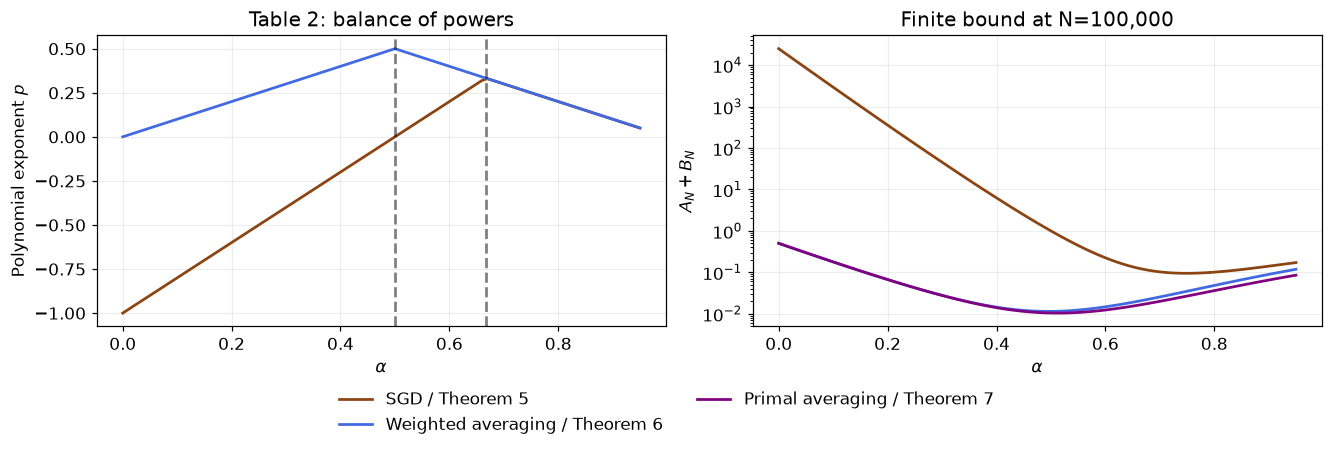

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(alpha_grid, polynomial_sgd, color="saddlebrown",
             linewidth=1.8, label="SGD")
axes[0].plot(alpha_grid, polynomial_avg, color="royalblue",
             linewidth=1.8, label="Averaging and primal averaging")
axes[0].axvline(2 / 3, color="black", linestyle="--", linewidth=1.8, alpha=0.5)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1.8, alpha=0.5)
axes[0].set(xlabel=r"$\alpha$", ylabel=r"Polynomial exponent $p$",
            title="Table 2: balance of powers")
for method in methods:
    axes[1].semilogy(alpha_grid, finite_bounds[method], color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
axes[1].set(xlabel=r"$\alpha$", ylabel=r"$A_N+B_N$",
            title=f"Finite bound at N={N_RATE:,}")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()

탐색한 격자에서 유한 합으로 계산한 상한을 최소화하는 값을

$$\alpha_N^{\mathrm{grid}}\in
\arg\min_{\alpha\in\{0,0.01,\ldots,0.95\}}
\left[A_N(\alpha)+B_N(\alpha)\right]$$

로 표시한다. 다음 표에서 이 값과 Table 2의 점근적 균형점을 비교한다.


In [47]:
headers = ["방법", r"격자의 최적 $\alpha$", "유한 합의 상한", r"Table 2의 $\alpha$"]
rows = []
for method in methods:
    best = np.argmin(finite_bounds[method])
    rows.append((method_labels[method], f"{alpha_grid[best]:.2f}",
                 f"{finite_bounds[method][best]:.6g}", f"{critical[method]:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | 격자의 최적 $\alpha$ | 유한 합의 상한 | Table 2의 $\alpha$ |
| --- | --- | --- | --- |
| SGD / Theorem 5 | 0.75 | 0.0944023 | 0.666667 |
| Weighted averaging / Theorem 6 | 0.50 | 0.0113729 | 0.5 |
| Primal averaging / Theorem 7 | 0.51 | 0.0103387 | 0.5 |

이 격자에서는 $N=10^5$의 상한이 SGD에서 $\alpha=0.75$, averaging에서 $0.50$, primal averaging에서 $0.51$일 때 가장 작다. SGD의 $0.75$는 상수와 로그의 영향까지 포함한 유한 합을 최소화한 값이다. Table 2의 $2/3$은 초기 거리 항과 분산 항의 점근적인 거듭제곱 지수를 균형 잡는 값이므로, 두 결과가 같을 필요는 없다.

두 평균법의 유한 $N$ 최소점은 점근적 균형점 $1/2$ 부근에 있다. 앞의 임계점 실험에서 본 로그 보정과 유한 합의 상수를 반영하면, 가까운 격자점 사이에서도 최소점이 달라질 수 있다.

지금까지 비교한 세 방법의 차이는 오차 계수에서 드러난다. 고정 step-size의 SGD에서는 함수값 계수가 커지는 동안 오차 계수도 함께 증가했다. Averaging은 그 증가를 억제했고, primal averaging은 평균점에서 oracle을 평가해 추가항까지 제거했다. 이 차이로 감소 step-size에서 선택할 $\alpha$가 바뀌며, 각 정리가 보장하는 수렴률도 $\widetilde O(N^{-1/3})$에서 $\widetilde O(N^{-1/2})$로 개선된다.


이로써 발표의 공통 흐름도 하나로 연결된다. GD에서는 potential 감소를 보장하는 계수를 수치적으로 찾고, 그 형태를 바탕으로 수렴률을 증명했다. SGD에서는 같은 분석에 분산 조건을 추가해 함수값 상한의 오차 항을 계산했다. Averaging에서는 상한의 오차 항을 줄이도록 알고리즘의 평균점과 oracle 평가점을 바꾼 뒤, 동일한 다섯 단계를 다시 적용했다. Table 2는 그렇게 얻은 해석적 부등식들을 공통 기준으로 모아 비교한 결과다.
